# TP — Chaînes de déploiement d'un modèle d'IA
## Pipeline CPU n°1 : PyTorch → ONNX → OpenVINO Runtime → CPU

| Niveau | Composant | Rôle dans ce notebook |
|---|---|---|
| **Haut niveau** | PyTorch | ResNet-18 pré-entraîné ImageNet, tête 10 classes (section 1) |
| **Format du modèle** | ONNX | export du graphe PyTorch en format pivot (section 4.1) |
| **Middle level** | OpenVINO Runtime | lecture ONNX, fusion d'opérateurs, choix des kernels, compilation pour le CPU (4.2–4.3) |
| **Bas niveau** | kernels CPU oneDNN (JIT AVX2 / AVX-512) | primitives réellement exécutées, visibles par profilage (4.5) |
| **Matériel** | CPU de Google Colab | 2 vCPU, environnement d'exécution « CPU » |

**Modèle** : ResNet-18 pré-entraîné ImageNet, 10 classes · **Données** : 50 images de test CIFAR-10 (5 par classe) · **Batch** : 10 · **Répétitions** : 10 passes mesurées + 3 mesures d'énergie.

### Avant de lancer
1. `Exécution` → `Modifier le type d'exécution` → **CPU**. Utiliser le même type pour le notebook du pipeline n°2.
2. `Exécution` → `Tout exécuter` et autoriser l'accès à Google Drive (dossier `MyDrive/TP_Deploiement_IA`, partagé avec l'autre notebook).
3. Durée : ≈ 10 min au premier lancement (téléchargement CIFAR-10 et création de la tête 10 classes), ≈ 6 min ensuite.

### Plan
0. Environnement · 1. Préparation commune · 2. Outils de mesure · 3. Référence PyTorch eager · 4. Pipeline ONNX → OpenVINO · 5. Résultats de ce pipeline · 6. Comparaison des pipelines · 7. Analyse

## 0. Environnement
### 0.1 Installation
`openvino` (runtime), `nncf` (quantification INT8 optionnelle), `onnx` / `onnxscript` (export), `psutil` (mesure CPU).

In [ ]:
!pip install -q openvino nncf onnx onnxscript psutil
!lscpu | grep -E "Model name|^CPU\(s\)|Thread|Core\(s\)|Socket|L3" ; grep -o -w -E "avx2|avx512f|avx512_vnni|amx_tile|avx512_bf16" /proc/cpuinfo | sort -u | tr "\n" " "

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Thread(s) per core:                      2
Core(s) per socket:                      1
Socket(s):                               1
L3 cache:                                55 MiB (1 instance)
avx2 

### 0.2 Configuration de l'expérience
Les paramètres expérimentaux sont **identiques dans les deux notebooks** (images, batch, warm-up, répétitions, threads, énergie).

In [ ]:
import os, json, time, math, copy, hashlib, datetime, warnings
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=UserWarning)

# ---------- Paramètres expérimentaux : IDENTIQUES dans les deux notebooks ----------
SEED = 42
N_IMAGES = 50            # images de test CIFAR-10
BATCH_SIZE = 10          # => 5 batches par passe
N_WARMUP = 5             # passes complètes non mesurées
N_RUNS = 10              # passes mesurées (>= 3 exigées)
ENERGY_MIN_SECONDS = 10.0
N_ENERGY_REPS = 3
N_THREADS = os.cpu_count()          # tous les vCPU, pour chaque moteur
CPU_POWER_PER_VCPU_W = 10.0         # HYPOTHÈSE utilisée seulement si RAPL est inaccessible

# ---------- Adaptation du modèle à 10 classes (si les poids n'existent pas encore) ----------
N_TRAIN_PER_CLASS = 300  # images d'entraînement par classe pour le linear probing
N_VAL = 500              # images de test (hors des 50) pour estimer la précision du modèle

# ---------- Stockage partagé par les deux notebooks (Google Drive) ----------
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/TP_Deploiement_IA"
else:
    ROOT = "/content/TP_Deploiement_IA"
SHARED, RESULTS, FIGS, WORK = f"{ROOT}/shared", f"{ROOT}/results", f"{ROOT}/figures", "/content/work"
for d in (SHARED, RESULTS, FIGS, WORK):
    os.makedirs(d, exist_ok=True)

PIPELINE_TAG = "ov"
SESSION_ID = PIPELINE_TAG + "_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
torch.manual_seed(SEED); np.random.seed(SEED)
torch.set_num_threads(N_THREADS)
if torch.cuda.is_available():
    print("⚠ Un GPU est attaché : choisissez un environnement CPU pour des mesures comparables.")
print("Session :", SESSION_ID, "| threads :", N_THREADS, "| dossier :", ROOT)

RUN_INT8 = True        # variante optionnelle : quantification INT8 post-entraînement (NNCF)
SESSION_REF_KEY = "cpu_ov_ref_eager"

Mounted at /content/drive
Session : ov_20261116-085931 | threads : 2 | dossier : /content/drive/MyDrive/TP_Deploiement_IA


### (Optionnel) Sans Google Drive : importer l'archive produite par l'autre notebook
Seulement si `USE_DRIVE = False` et que l'autre notebook a déjà été exécuté : importez `TP_Deploiement_IA.zip` (dernière cellule de l'autre notebook). Sinon, ignorez cette cellule.

In [ ]:
if not USE_DRIVE and not os.path.exists(f"{SHARED}/cifar10_test50.pt"):
    import zipfile
    from google.colab import files
    print("Importez TP_Deploiement_IA.zip (ou annulez si c'est le premier notebook exécuté).")
    try:
        up = files.upload()
        with zipfile.ZipFile(next(iter(up))) as z:
            z.extractall(ROOT)
    except Exception as e:
        print("Aucune archive importée :", e)

### 0.3 Informations sur l'environnement (enregistrées avec chaque résultat)

In [ ]:
import os, platform, subprocess

def _cpu_model():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor()

def get_env_info():
    import torch, torchvision
    info = {"python": platform.python_version(), "torch": torch.__version__,
            "torchvision": torchvision.__version__, "cpu": _cpu_model(), "n_vcpu": os.cpu_count(),
            "torch_threads": torch.get_num_threads()}
    if torch.cuda.is_available():
        info.update({"cuda": torch.version.cuda, "cudnn": torch.backends.cudnn.version(),
                     "gpu": torch.cuda.get_device_name(0),
                     "compute_capability": ".".join(map(str, torch.cuda.get_device_capability(0)))})
        try:
            info["nvidia_driver"] = subprocess.check_output(
                ["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"]).decode().strip()
        except Exception:
            pass
    return info

ENV = get_env_info()
import openvino as ov
ENV["openvino"] = ov.__version__
for k, v in ENV.items():
    print(f"{k:>20} : {v}")

              python : 3.13.18
               torch : 2.14.1+cpu
         torchvision : 0.29.1+cpu
                 cpu : Intel(R) Xeon(R) CPU @ 2.20GHz
              n_vcpu : 2
       torch_threads : 2
            openvino : 2026.4.1-22982-e213a147257-releases/2026/4


## 1. Préparation commune : modèle et données (identique dans les deux notebooks)

Cette section est **la même dans les deux notebooks**. Le premier notebook exécuté crée les fichiers dans `Drive/TP_Deploiement_IA/shared` ; le second les **recharge** au lieu de les recréer. Les deux pipelines utilisent donc exactement le même modèle et les mêmes octets d'entrée (contrôle par empreinte SHA-256).

**Données** : 50 images du jeu de **test** CIFAR-10, tirées avec une graine fixe, **5 par classe** (sous-ensemble équilibré).

**Prétraitement** (fonction unique `preprocess_uint8`) :
1. `uint8 [0,255]` → `float32 [0,1]` ;
2. redimensionnement **32×32 → 224×224** (bilinéaire), résolution d'entraînement de ResNet-18 ;
3. normalisation avec les statistiques ImageNet du pré-entraînement : `mean=(0.485, 0.456, 0.406)`, `std=(0.229, 0.224, 0.225)`.

**Modèle à 10 classes** : ResNet-18 pré-entraîné ImageNet sort 1000 classes. On garde tout le réseau pré-entraîné **gelé** et on remplace la dernière couche `fc` (512 → 1000) par une couche 512 → 10 apprise sur des images d'**entraînement** CIFAR-10 (*linear probing*, ≈ 2–3 min sur CPU). Si un fichier de poids existe déjà dans `shared` (par exemple créé par le notebook GPU d'un binôme), il est réutilisé tel quel.

In [ ]:
# ---------- Modèle et prétraitement (définitions communes) ----------
from torchvision.models import resnet18, ResNet18_Weights

NUM_CLASSES = 10
IMG_SIZE = 224
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

def build_model(num_classes=NUM_CLASSES, pretrained=True):
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

def preprocess_uint8(x_uint8_nhwc):
    # uint8 [N,32,32,3] -> float32 [N,3,224,224] normalisé ImageNet
    x = x_uint8_nhwc.permute(0, 3, 1, 2).float().div(255.0)
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    mean = torch.tensor(MEAN, device=x.device).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std

PREPROCESSING = {"resize": [IMG_SIZE, IMG_SIZE], "interpolation": "bilinear, align_corners=False",
                 "scale": "1/255", "mean": list(MEAN), "std": list(STD), "layout": "NCHW float32"}

TEST50_PATH = f"{SHARED}/cifar10_test50.pt"
WEIGHTS_PATH = f"{SHARED}/resnet18_cifar10.pth"
MODEL_INFO_PATH = f"{SHARED}/model_info.json"
ONNX_PATH = f"{SHARED}/resnet18_cifar10.onnx"

train_set = torchvision.datasets.CIFAR10("/content/data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10("/content/data", train=False, download=True)
CLASSES = test_set.classes

100%|██████████| 170M/170M [45:04<00:00, 63.1kB/s]


Sous-ensemble créé : /content/drive/MyDrive/TP_Deploiement_IA/shared/cifar10_test50.pt
Images : (50, 3, 224, 224) torch.float32 | par classe : [5 5 5 5 5 5 5 5 5 5]
Indices CIFAR-10 (test) : [347, 883, 1020, 1216, 1381, 1626, 1658, 1870, 2285, 2786, 3138, 3316, 3534, 3802, 4064, 4244, 4297, 4374, 4426, 4492, 4542, 4589, 4609, 4623, 4811, 5052, 5217, 5486, 5501, 6056, 6274, 6574, 6733, 6999, 7075, 7450, 7527, 7638, 7662, 7701, 8118, 8181, 8363, 8430, 8452, 8901, 9149, 9651, 9652, 9763]
SHA-256 des entrées : 117a8d622a1424ccdda5f77c957bd3794f6b3a54ff4d94a690b53d19052a30f9


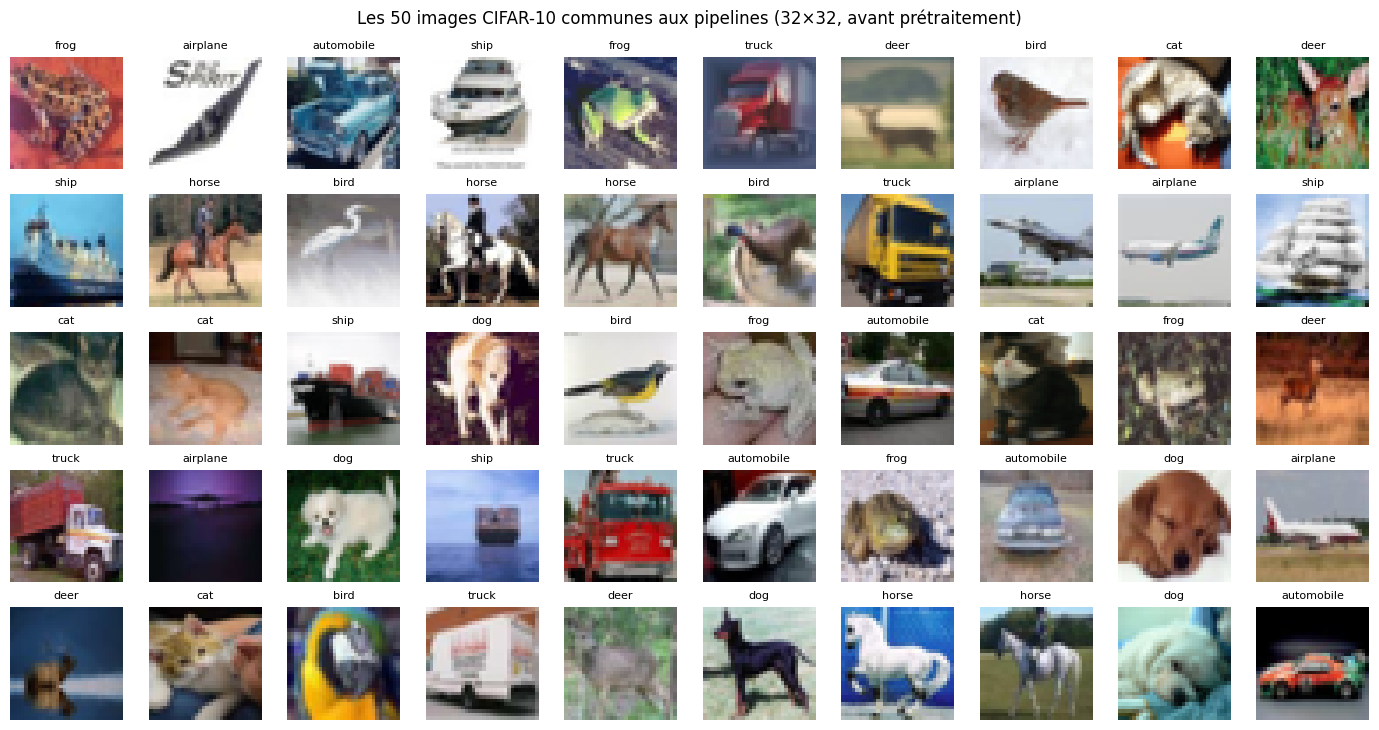

In [ ]:
# ---------- 1.1 Sous-ensemble des 50 images (créé une seule fois, puis rechargé) ----------
if not os.path.exists(TEST50_PATH):
    labels_test = np.array(test_set.targets)
    rng = np.random.default_rng(SEED)
    idx = np.sort(np.concatenate([
        rng.choice(np.where(labels_test == c)[0], N_IMAGES // NUM_CLASSES, replace=False)
        for c in range(NUM_CLASSES)]))
    x50_uint8 = torch.from_numpy(test_set.data[idx])
    y50 = torch.from_numpy(labels_test[idx]).long()
    x50 = preprocess_uint8(x50_uint8).contiguous()
    torch.save({"images": x50, "labels": y50, "images_uint8": x50_uint8, "indices": idx.tolist(),
                "classes": CLASSES, "preprocessing": PREPROCESSING,
                "sha256": hashlib.sha256(x50.numpy().tobytes()).hexdigest()}, TEST50_PATH)
    print("Sous-ensemble créé :", TEST50_PATH)
else:
    print("Sous-ensemble existant rechargé :", TEST50_PATH)

T50 = torch.load(TEST50_PATH, weights_only=False)
X50, Y50 = T50["images"].contiguous(), T50["labels"]
Y50_NP = Y50.numpy()
X50_NP = np.ascontiguousarray(X50.numpy())
TEST_SHA = hashlib.sha256(X50.numpy().tobytes()).hexdigest()
assert TEST_SHA == T50["sha256"], "Empreinte des images incohérente"
assert T50["preprocessing"] == PREPROCESSING, "Paramètres de prétraitement différents"
print("Images :", tuple(X50.shape), X50.dtype, "| par classe :", np.bincount(Y50_NP))
print("Indices CIFAR-10 (test) :", T50["indices"])
print("SHA-256 des entrées :", TEST_SHA)

fig, axes = plt.subplots(5, 10, figsize=(14, 7.4))
for ax, img, lab in zip(axes.ravel(), T50["images_uint8"], Y50_NP):
    ax.imshow(img.numpy()); ax.set_title(CLASSES[lab], fontsize=8); ax.axis("off")
fig.suptitle("Les 50 images CIFAR-10 communes aux pipelines (32×32, avant prétraitement)")
plt.tight_layout(); plt.show()

In [ ]:
# ---------- 1.2 Modèle 10 classes (créé une seule fois, puis rechargé) ----------
@torch.no_grad()
def extract_features(backbone, x_uint8, bs=100):
    out = []
    for i in range(0, len(x_uint8), bs):
        out.append(backbone(preprocess_uint8(torch.from_numpy(x_uint8[i:i + bs]))).flatten(1))
    return torch.cat(out)

if not os.path.exists(WEIGHTS_PATH):
    print("Création de la tête 10 classes par linear probing (réseau pré-entraîné gelé)…")
    torch.manual_seed(SEED)
    model = build_model(pretrained=True).eval()
    backbone = nn.Sequential(*list(model.children())[:-1]).eval()     # tout sauf fc -> [N,512,1,1]
    rng = np.random.default_rng(SEED)
    ytr_all, yte_all = np.array(train_set.targets), np.array(test_set.targets)
    tr_idx = np.sort(np.concatenate([rng.choice(np.where(ytr_all == c)[0], N_TRAIN_PER_CLASS, replace=False)
                                     for c in range(NUM_CLASSES)]))
    pool = np.setdiff1d(np.arange(len(yte_all)), np.array(T50["indices"]))   # jamais les 50 images
    va_idx = np.sort(rng.choice(pool, N_VAL, replace=False))
    t0 = time.time()
    f_tr = extract_features(backbone, train_set.data[tr_idx])
    f_va = extract_features(backbone, test_set.data[va_idx])
    print(f"Extraction des caractéristiques : {time.time() - t0:.0f} s")
    y_tr, y_va = torch.from_numpy(ytr_all[tr_idx]).long(), torch.from_numpy(yte_all[va_idx]).long()
    head = nn.Linear(512, NUM_CLASSES)
    opt = torch.optim.Adam(head.parameters(), lr=1e-2, weight_decay=1e-4)
    for it in range(500):
        opt.zero_grad()
        loss = F.cross_entropy(head(f_tr), y_tr)
        loss.backward(); opt.step()
    with torch.no_grad():
        acc_tr = (head(f_tr).argmax(1) == y_tr).float().mean().item() * 100
        acc_va = (head(f_va).argmax(1) == y_va).float().mean().item() * 100
    print(f"Tête 10 classes : perte {loss.item():.3f} | Top-1 entraînement {acc_tr:.1f} % | validation {acc_va:.1f} %")
    model.fc.load_state_dict(head.state_dict())
    torch.save(model.state_dict(), WEIGHTS_PATH)
    with open(MODEL_INFO_PATH, "w") as f:
        json.dump({"base": "torchvision resnet18 IMAGENET1K_V1 (gelé)", "head": "Linear(512,10)",
                   "method": "linear probing", "train_images": int(len(tr_idx)),
                   "val_images": int(len(va_idx)), "val_top1_pct": acc_va}, f, indent=2)
    del model, backbone, f_tr, f_va
else:
    print("Poids existants rechargés :", WEIGHTS_PATH)

model_ref = build_model(pretrained=False)
model_ref.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
model_ref.eval()
if os.path.exists(MODEL_INFO_PATH):
    with open(MODEL_INFO_PATH) as f:
        print("Modèle :", json.load(f))

Création de la tête 10 classes par linear probing (réseau pré-entraîné gelé)…
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 118MB/s]


Extraction des caractéristiques : 376 s
Tête 10 classes : perte 0.049 | Top-1 entraînement 99.9 % | validation 80.8 %
Modèle : {'base': 'torchvision resnet18 IMAGENET1K_V1 (gelé)', 'head': 'Linear(512,10)', 'method': 'linear probing', 'train_images': 3000, 'val_images': 500, 'val_top1_pct': 80.80000281333923}


## 2. Outils de mesure (identiques dans les deux notebooks)

**Protocole commun à tous les pipelines :**
* 50 images → **5 batches de 10**, entrées prétraitées une fois pour toutes (le prétraitement n'est pas chronométré) ;
* **5 passes de warm-up** non mesurées : allocations mémoire, compilation JIT / optimisation de graphe à la volée, remplissage des caches ;
* **10 passes mesurées** (≥ 3 exigées) chronométrées avec `time.perf_counter()` ;
* par passe : **temps d'inférence** des 50 images, **débit** = 50 / temps (images/s), **latence par batch** (moyenne, médiane, max), **précision Top-1**, accord avec la 1re passe ;
* pour chaque indicateur : **moyenne, écart-type, minimum, maximum, coefficient de variation** (CV = σ / moyenne) ;
* chaque exécution complète du notebook est enregistrée dans `results/history/` : relancer le notebook dans une nouvelle session ajoute une **exécution indépendante** (voir la dernière section).

**Énergie CPU** :
* **RAPL** (*Running Average Power Limit*, compteur d'énergie du package CPU dans `/sys/class/powercap`) est utilisé s'il est accessible → valeur **mesurée** ;
* sur les VM Colab, RAPL n'est en général **pas exposé** ; on calcule alors une **estimation** `E ≈ P_vCPU × temps CPU actif`, où le temps CPU actif (somme sur tous les vCPU) est lu par `psutil` et `P_vCPU = CPU_POWER_PER_VCPU_W` (hypothèse : un Xeon serveur ≈ 200 W pour 20–40 threads, soit ≈ 5–10 W par thread actif).
* La méthode utilisée est enregistrée avec chaque résultat. ⚠ Une estimation doit être présentée comme telle dans le rapport : elle est proportionnelle au temps CPU consommé, donc elle compare correctement les pipelines entre eux, mais sa valeur absolue dépend de l'hypothèse.

In [ ]:
# ============================================================
# Outils de mesure — IDENTIQUES dans les deux notebooks
# ============================================================
import os, time, json, datetime, glob
import numpy as np

def _to_py(o):
    # Conversion récursive numpy -> types Python (pour json.dump)
    if isinstance(o, dict):
        return {k: _to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_to_py(v) for v in o]
    if isinstance(o, np.generic):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    return o

def describe(values):
    # Moyenne, écart-type (échantillon, ddof=1), min, max, coefficient de variation
    a = np.asarray(values, dtype=float)
    mean = float(a.mean())
    std = float(a.std(ddof=1)) if a.size > 1 else 0.0
    return {"mean": mean, "std": std, "min": float(a.min()), "max": float(a.max()),
            "cv_pct": (100.0 * std / mean) if mean else 0.0, "n": int(a.size)}

def to_numpy(out):
    if isinstance(out, np.ndarray):
        return out
    return out.detach().float().cpu().numpy()

def make_batches(images, batch_size):
    return [images[i:i + batch_size] for i in range(0, len(images), batch_size)]

def run_pass(infer_fn, batches, sync_fn, keep_outputs=True):
    # Une passe complète sur les 50 images. sync_fn() garantit que le calcul
    # est terminé avant d'arrêter le chronomètre (indispensable sur GPU : CUDA est asynchrone).
    outs, lat = [], []
    t0 = time.perf_counter()
    for xb in batches:
        ts = time.perf_counter()
        out = infer_fn(xb)
        sync_fn()
        lat.append(time.perf_counter() - ts)
        if keep_outputs:
            outs.append(out)
    return time.perf_counter() - t0, lat, outs

RUN_METRICS = ["total_time_ms", "throughput_img_s", "batch_latency_mean_ms",
               "batch_latency_p50_ms", "batch_latency_max_ms", "per_image_time_ms",
               "top1_acc_pct", "agreement_with_run0_pct"]
ENERGY_METRICS = ["energy_per_image_mj", "net_energy_per_image_mj", "mean_power_w",
                  "energy_j", "duration_s"]

def benchmark(infer_fn, images, labels_np, sync_fn, batch_size=None, n_warmup=None, n_runs=None):
    batch_size = batch_size or BATCH_SIZE
    n_warmup = N_WARMUP if n_warmup is None else n_warmup
    n_runs = n_runs or N_RUNS
    batches = make_batches(images, batch_size)
    n = sum(len(b) for b in batches)
    # 1) Warm-up : non mesuré (allocations, autotuning cuDNN, compilation JIT, montée en fréquence)
    for _ in range(n_warmup):
        run_pass(infer_fn, batches, sync_fn, keep_outputs=False)
    # 2) Répétitions mesurées
    runs, logits0 = [], None
    for r in range(n_runs):
        total, lat, outs = run_pass(infer_fn, batches, sync_fn)
        logits = np.concatenate([to_numpy(o) for o in outs]).astype(np.float32)
        preds = logits.argmax(1)
        if logits0 is None:
            logits0 = logits
        lat_ms = np.asarray(lat) * 1e3
        runs.append({
            "run": r,
            "total_time_ms": total * 1e3,
            "throughput_img_s": n / total,
            "batch_latency_mean_ms": float(lat_ms.mean()),
            "batch_latency_p50_ms": float(np.percentile(lat_ms, 50)),
            "batch_latency_max_ms": float(lat_ms.max()),
            "per_image_time_ms": total * 1e3 / n,
            "top1_acc_pct": float((preds == labels_np).mean() * 100),
            "agreement_with_run0_pct": float((preds == logits0.argmax(1)).mean() * 100),
        })
    return runs, logits0

def measure_energy(infer_fn, images, sync_fn, meter_factory, idle_power_w=0.0,
                   batch_size=None, min_seconds=None, n_reps=None):
    # Boucle de passes complètes pendant au moins `min_seconds` secondes,
    # pour que la mesure d'énergie couvre une durée exploitable.
    batch_size = batch_size or BATCH_SIZE
    min_seconds = min_seconds or ENERGY_MIN_SECONDS
    n_reps = n_reps or N_ENERGY_REPS
    batches = make_batches(images, batch_size)
    n = sum(len(b) for b in batches)
    reps = []
    for r in range(n_reps):
        n_img = 0
        with meter_factory() as m:
            t0 = time.perf_counter()
            while time.perf_counter() - t0 < min_seconds:
                run_pass(infer_fn, batches, sync_fn, keep_outputs=False)
                n_img += n
        e, dur = m.energy_j, m.duration_s
        reps.append({"rep": r, "method": m.method, "energy_j": e, "duration_s": dur,
                     "images": n_img, "mean_power_w": e / dur,
                     "energy_per_image_mj": 1e3 * e / n_img,
                     "net_energy_per_image_mj": 1e3 * max(e - idle_power_w * dur, 0.0) / n_img})
    return reps

def save_result(key, label, platform_name, family, precision, runs, logits,
                energy_reps=None, idle_power_w=None, extra=None):
    res = {
        "key": key, "label": label, "platform": platform_name, "family": family,
        "precision": precision, "batch_size": BATCH_SIZE, "n_images": int(len(logits)),
        "n_warmup": N_WARMUP, "n_runs": len(runs), "runs": runs,
        "summary": {m: describe([r[m] for r in runs]) for m in RUN_METRICS},
        "energy": None, "env": ENV, "test_sha256": TEST_SHA, "extra": extra or {},
        "session_id": globals().get("SESSION_ID"), "session_ref_key": globals().get("SESSION_REF_KEY"),
        "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    }
    if energy_reps:
        res["energy"] = {"method": energy_reps[0]["method"], "idle_power_w": idle_power_w,
                         "reps": energy_reps,
                         "summary": {m: describe([e[m] for e in energy_reps]) for m in ENERGY_METRICS}}
    np.save(f"{RESULTS}/{key}_logits.npy", logits)
    with open(f"{RESULTS}/{key}.json", "w") as f:
        json.dump(_to_py(res), f, indent=2, ensure_ascii=False)
    # historique : une copie par session, pour analyser la variabilité entre exécutions indépendantes
    os.makedirs(f"{RESULTS}/history", exist_ok=True)
    with open(f"{RESULTS}/history/{key}__{res['session_id']}.json", "w") as f:
        json.dump(_to_py(res), f, indent=2, ensure_ascii=False)
    s = res["summary"]
    msg = (f"[{label}] débit = {s['throughput_img_s']['mean']:.1f} ± {s['throughput_img_s']['std']:.1f} img/s"
           f" | latence/batch = {s['batch_latency_mean_ms']['mean']:.2f} ± {s['batch_latency_mean_ms']['std']:.2f} ms"
           f" | Top-1 = {s['top1_acc_pct']['mean']:.1f} %")
    if res["energy"]:
        msg += f" | énergie/image = {res['energy']['summary']['energy_per_image_mj']['mean']:.2f} mJ"
    print(msg)
    return res

def evaluate_pipeline(key, label, platform_name, family, precision, infer_fn, images, sync_fn,
                      meter_factory=None, idle_power_w=0.0, extra=None):
    runs, logits = benchmark(infer_fn, images, Y50_NP, sync_fn)
    reps = measure_energy(infer_fn, images, sync_fn, meter_factory, idle_power_w) if meter_factory else None
    return save_result(key, label, platform_name, family, precision, runs, logits,
                       energy_reps=reps, idle_power_w=idle_power_w, extra=extra)

print("Outils de mesure prêts.")

Outils de mesure prêts.


In [ ]:
# ---------- Mesure d'énergie CPU (RAPL si disponible, sinon estimation) ----------
import psutil

def _rapl_zones():
    zones = []
    for d in sorted(glob.glob("/sys/class/powercap/intel-rapl:*")):
        if os.path.basename(d).count(":") != 1:      # zones « package » uniquement
            continue
        try:
            with open(f"{d}/energy_uj") as f:
                int(f.read())
            with open(f"{d}/max_energy_range_uj") as f:
                zones.append((d, int(f.read())))
        except Exception:
            pass
    return zones
RAPL_ZONES = _rapl_zones()

def _busy_seconds(ct):
    return sum(getattr(ct, f, 0.0) for f in ("user", "nice", "system", "irq", "softirq"))

class CpuEnergyMeter:
    def _read_rapl(self):
        vals = []
        for d, _ in RAPL_ZONES:
            with open(f"{d}/energy_uj") as f:
                vals.append(int(f.read()))
        return vals
    def __enter__(self):
        self._ct0 = psutil.cpu_times()
        self._r0 = self._read_rapl() if RAPL_ZONES else None
        self._t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        self.duration_s = time.perf_counter() - self._t0
        self.busy_cpu_s = _busy_seconds(psutil.cpu_times()) - _busy_seconds(self._ct0)
        self.cpu_util_pct = 100 * self.busy_cpu_s / (self.duration_s * psutil.cpu_count())
        if RAPL_ZONES:
            e = 0
            for (d, mx), a, b in zip(RAPL_ZONES, self._r0, self._read_rapl()):
                e += (b - a) if b >= a else (b + mx - a)     # débordement du compteur
            self.energy_j = e / 1e6
            self.method = "RAPL : package CPU (mesuré)"
        else:
            self.energy_j = CPU_POWER_PER_VCPU_W * self.busy_cpu_s
            self.method = f"Estimation : {CPU_POWER_PER_VCPU_W:g} W par vCPU actif × temps CPU actif"
        return False

def measure_idle_power_cpu(seconds=5.0):
    if not RAPL_ZONES:
        return 0.0          # l'estimation ne compte que le temps CPU actif
    time.sleep(1.0)
    with CpuEnergyMeter() as m:
        time.sleep(seconds)
    return m.energy_j / m.duration_s

def no_sync():
    pass                    # exécution CPU synchrone : rien à attendre

IDLE_W = measure_idle_power_cpu()
print("RAPL accessible :", bool(RAPL_ZONES), "|",
      f"puissance de repos {IDLE_W:.1f} W" if RAPL_ZONES else "énergie estimée (voir hypothèse)")

RAPL accessible : False | énergie estimée (voir hypothèse)


## 3. Référence : PyTorch eager FP32 (dans cette session)
Le même modèle exécuté directement par PyTorch, opérateur par opérateur. Cette référence, mesurée **sur la même machine**, sert à calculer l'accélération apportée par OpenVINO et à vérifier que ses prédictions sont identiques.

In [ ]:
model_eager = copy.deepcopy(model_ref).eval()

@torch.inference_mode()
def infer_eager(x):
    return model_eager(x)

res_ref = evaluate_pipeline("cpu_ov_ref_eager", "Réf. eager FP32 (session OV)", "CPU", "reference", "FP32",
                            infer_eager, X50, no_sync, CpuEnergyMeter, IDLE_W)

[Réf. eager FP32 (session OV)] débit = 11.0 ± 2.3 img/s | latence/batch = 954.73 ± 228.97 ms | Top-1 = 90.0 % | énergie/image = 1895.78 mJ


## 4. Pipeline CPU n°1 : PyTorch → ONNX → OpenVINO Runtime → CPU

### 4.1 Format du modèle : export ONNX
* `opset 17`, axe batch dynamique, *constant folding* ; validation par `onnx.checker` ;
* comptage des nœuds du graphe ONNX : point de départ pour mesurer la **fusion d'opérateurs** faite par OpenVINO ;
* si le fichier existe déjà (créé par un autre notebook à partir des mêmes poids), il est réutilisé.

In [ ]:
import onnx
from collections import Counter

if not os.path.exists(ONNX_PATH):
    kw = dict(input_names=["input"], output_names=["logits"], opset_version=17, do_constant_folding=True,
              dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}})
    dummy = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE)
    t0 = time.perf_counter()
    try:
        torch.onnx.export(model_ref, dummy, ONNX_PATH, dynamo=False, **kw)
    except TypeError:
        torch.onnx.export(model_ref, dummy, ONNX_PATH, **kw)
    print(f"Export ONNX : {time.perf_counter() - t0:.1f} s")
onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)
N_ONNX_NODES = len(onnx_model.graph.node)
ONNX_OPS = Counter(n.op_type for n in onnx_model.graph.node)
print(f"{ONNX_PATH} — {os.path.getsize(ONNX_PATH) / 1e6:.1f} Mo — {N_ONNX_NODES} nœuds")
print("Opérateurs ONNX :", dict(ONNX_OPS))

/tmp/ipykernel_2169/3409219339.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_ref, dummy, ONNX_PATH, dynamo=False, **kw)


Export ONNX : 1.7 s
/content/drive/MyDrive/TP_Deploiement_IA/shared/resnet18_cifar10.onnx — 44.7 Mo — 49 nœuds
Opérateurs ONNX : {'Conv': 20, 'Relu': 17, 'MaxPool': 1, 'Add': 8, 'GlobalAveragePool': 1, 'Flatten': 1, 'Gemm': 1}


### 4.2 Middle level : lecture et compilation par OpenVINO Runtime
* `core.read_model` convertit le graphe ONNX en représentation intermédiaire OpenVINO ;
* `core.compile_model(…, "CPU")` applique les optimisations du *plugin CPU* : fusion Conv + BatchNorm + ReLU (+ addition résiduelle), choix de la disposition mémoire (blocs NCHW8c/16c adaptés aux registres vectoriels), sélection pour chaque couche d'une primitive **oneDNN** adaptée au jeu d'instructions ;
* configuration : `N_THREADS` threads, mode **LATENCY** (une requête à la fois, comme les autres pipelines), précision forcée **FP32** (sur certains CPU récents, OpenVINO passerait sinon en BF16, ce qui fausserait la comparaison).

In [ ]:
core = ov.Core()
print("Périphériques OpenVINO :", core.available_devices,
      "|", core.get_property("CPU", "FULL_DEVICE_NAME"))

try:
    import openvino.properties as props
    import openvino.properties.hint as hints
    OV_CFG_FP32 = {props.inference_num_threads: N_THREADS, hints.inference_precision: ov.Type.f32,
                   hints.performance_mode: hints.PerformanceMode.LATENCY}
    OV_CFG_BASE = {props.inference_num_threads: N_THREADS, hints.performance_mode: hints.PerformanceMode.LATENCY}
    PROFILING_KEY = props.enable_profiling
except Exception:
    OV_CFG_FP32 = {"INFERENCE_NUM_THREADS": str(N_THREADS), "INFERENCE_PRECISION_HINT": "f32",
                   "PERFORMANCE_HINT": "LATENCY"}
    OV_CFG_BASE = {"INFERENCE_NUM_THREADS": str(N_THREADS), "PERFORMANCE_HINT": "LATENCY"}
    PROFILING_KEY = "PERF_COUNT"

t0 = time.perf_counter()
ov_model = core.read_model(ONNX_PATH)
read_s = time.perf_counter() - t0
t0 = time.perf_counter()
compiled_fp32 = core.compile_model(ov_model, "CPU", OV_CFG_FP32)
compile_s = time.perf_counter() - t0
print(f"read_model : {read_s:.2f} s | compile_model : {compile_s:.2f} s")
print("Précision d'exécution effective :", compiled_fp32.get_property("INFERENCE_PRECISION_HINT"),
      "| threads :", compiled_fp32.get_property("INFERENCE_NUM_THREADS"))

Périphériques OpenVINO : ['CPU'] |            Intel(R) Xeon(R) CPU @ 2.20GHz
read_model : 0.36 s | compile_model : 0.83 s
Précision d'exécution effective : <Type: 'float32'> | threads : 1


### 4.3 Ce qu'OpenVINO a fait du graphe : fusion d'opérateurs et sélection des kernels
Le **modèle d'exécution** (`get_runtime_model`) décrit le graphe réellement exécuté : nombre de couches après fusion, et, pour chaque couche, le type de primitive oneDNN choisi (`primitiveType`, par exemple `brgconv_avx512`, `jit_avx2`…).

In [ ]:
def _rt(rt, key):
    try:
        v = rt[key]
    except Exception:
        return None
    for conv in (lambda a: a.astype(str), lambda a: a.value, str):
        try:
            return conv(v)
        except Exception:
            pass
    return None

def runtime_layers(compiled):
    rows = []
    for op in compiled.get_runtime_model().get_ordered_ops():
        rt = op.get_rt_info()
        rows.append({"couche": op.get_friendly_name(), "type": _rt(rt, "layerType"),
                     "kernel": _rt(rt, "primitiveType"), "précision": _rt(rt, "runtimePrecision")})
    return pd.DataFrame(rows)

import pandas as pd
rt_df = runtime_layers(compiled_fp32)
exec_df = rt_df[~rt_df["type"].isin(["Input", "Output", "Parameter", "Result"])]
print(f"Nœuds ONNX : {N_ONNX_NODES}  →  couches exécutées par OpenVINO : {len(exec_df)}")
print("Couches ONNX par type :", dict(ONNX_OPS))
print("Couches OpenVINO par type :", dict(Counter(exec_df["type"])))
print("Kernels sélectionnés :", dict(Counter(exec_df["kernel"])))
print("Précisions :", dict(Counter(exec_df["précision"])))
exec_df.head(15)

Nœuds ONNX : 49  →  couches exécutées par OpenVINO : 110
Couches ONNX par type : {'Conv': 20, 'Relu': 17, 'MaxPool': 1, 'Add': 8, 'GlobalAveragePool': 1, 'Flatten': 1, 'Gemm': 1}
Couches OpenVINO par type : {'Reorder': 2, 'Const': 64, 'Reshape': 21, 'Convolution': 20, 'Pooling': 1, 'Reduce': 1, 'FullyConnected': 1}
Kernels sélectionnés : {'reorder_f32': 2, 'unknown_f32': 63, 'unknown_i32': 22, 'brgconv_avx2_f32': 17, 'jit_avx2_f32': 2, 'brgconv_avx2_1x1_f32': 3, 'undef_f32': 1}
Précisions : {'f32': 88, 'i32': 22}


,couche,type,kernel,précision
1,input_abcd_acdb_/conv1/Conv/WithoutBiases,Reorder,reorder_f32,f32
2,onnx::Conv_193,Const,unknown_f32,f32
3,Reshape_15,Const,unknown_f32,f32
4,Constant_6625,Const,unknown_i32,i32
5,Reshape_15_flatten_reshape,Reshape,unknown_f32,f32
6,/conv1/Conv/WithoutBiases,Convolution,brgconv_avx2_f32,f32
7,/maxpool/MaxPool,Pooling,jit_avx2_f32,f32
8,onnx::Conv_196,Const,unknown_f32,f32
9,Reshape_32,Const,unknown_f32,f32
10,Constant_6628,Const,unknown_i32,i32


### 4.4 Contrôle numérique puis mesures (OpenVINO FP32)
On vérifie d'abord que les sorties d'OpenVINO coïncident avec celles de PyTorch, puis on applique **exactement le même protocole** que pour la référence.

In [ ]:
ov_req = compiled_fp32.create_infer_request()
ov_out = compiled_fp32.output(0)

def infer_ov_fp32(x):
    return ov_req.infer({0: x})[ov_out].copy()

with torch.inference_mode():
    ref_logits = model_ref(X50).numpy()
ov_logits = np.concatenate([infer_ov_fp32(X50_NP[i:i + BATCH_SIZE]) for i in range(0, N_IMAGES, BATCH_SIZE)])
print(f"max |logit PyTorch − logit OpenVINO| = {np.abs(ref_logits - ov_logits).max():.2e} | "
      f"accord Top-1 = {100 * (ref_logits.argmax(1) == ov_logits.argmax(1)).mean():.0f} %")

res_ov = evaluate_pipeline("cpu1_openvino_fp32", "CPU-1 OpenVINO FP32", "CPU", "pipeline1", "FP32",
                           infer_ov_fp32, X50_NP, no_sync, CpuEnergyMeter, IDLE_W,
                           extra={"read_model_s": read_s, "compile_model_s": compile_s,
                                  "onnx_nodes": N_ONNX_NODES, "ov_exec_layers": int(len(exec_df)),
                                  "kernels": dict(Counter(exec_df["kernel"])), "openvino": ov.__version__})

max |logit PyTorch − logit OpenVINO| = 3.58e-05 | accord Top-1 = 100 %
[CPU-1 OpenVINO FP32] débit = 13.6 ± 2.3 img/s | latence/batch = 754.95 ± 139.99 ms | Top-1 = 90.0 % | énergie/image = 1038.89 mJ


### 4.5 Bas niveau : où passe le temps ? (profilage par couche OpenVINO)
Le profilage interne (`PERF_COUNT`) donne pour chaque couche exécutée son **type**, le **kernel oneDNN** utilisé (`exec_type`) et son **temps**. Il est fait sur une copie compilée séparément, pour ne pas perturber les mesures ci-dessus.

Temps total profilé pour un batch de 10 : 614.1 ms


sum  count  part_%
type           kernel                                     
Convolution    brgconv_avx2_f32      599.30     17   97.58
               brgconv_avx2_1x1_f32    7.62      3    1.24
MaxPool        jit_avx2_f32            5.74      1    0.93
Reorder        jit_uni_f32             1.16      2    0.19
ReduceMean     jit_avx2_f32            0.27      1    0.04
FullyConnected gemm_mlas_f32           0.05      1    0.01

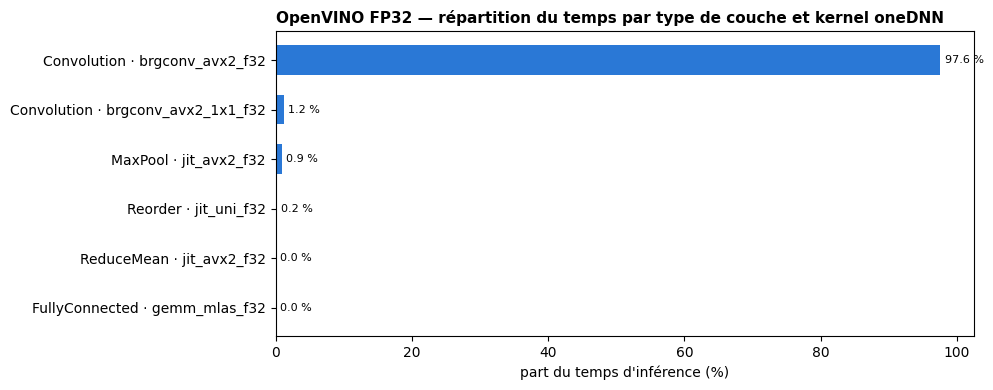

In [ ]:
prof_compiled = core.compile_model(core.read_model(ONNX_PATH), "CPU", {**OV_CFG_FP32, PROFILING_KEY: True})
prof_req = prof_compiled.create_infer_request()
for _ in range(5):
    prof_req.infer({0: X50_NP[:BATCH_SIZE]})
prof = pd.DataFrame([{"couche": p.node_name, "type": p.node_type, "kernel": p.exec_type,
                      "temps_ms": p.real_time.total_seconds() * 1e3}
                     for p in (getattr(prof_req, "profiling_info", None) or prof_req.get_profiling_info())])
prof = prof[prof["temps_ms"] > 0]
by_type = prof.groupby(["type", "kernel"])["temps_ms"].agg(["sum", "count"]).sort_values("sum", ascending=False)
by_type["part_%"] = 100 * by_type["sum"] / by_type["sum"].sum()
print(f"Temps total profilé pour un batch de {BATCH_SIZE} : {prof['temps_ms'].sum():.1f} ms")
display(by_type.round(2))

top = by_type.head(8)[::-1]
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh([f"{t} · {k}" for t, k in top.index], top["part_%"], color="#2a78d6", height=0.6)
for i, v in enumerate(top["part_%"]):
    ax.annotate(f"{v:.1f} %", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_xlabel("part du temps d'inférence (%)")
ax.set_title("OpenVINO FP32 — répartition du temps par type de couche et kernel oneDNN", loc="left",
             fontsize=11, fontweight="bold")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(f"{FIGS}/ov_profil_couches.png", bbox_inches="tight"); plt.show()
del prof_req, prof_compiled

### 4.6 (Optionnel) Variante OpenVINO INT8 — quantification post-entraînement (NNCF)
NNCF calibre les plages de valeurs sur **300 images d'entraînement** (jamais les 50 images de test), puis insère des opérations de quantification : les convolutions s'exécutent en **entiers 8 bits** (instructions VNNI si le CPU les possède). Cette variante montre le compromis vitesse / exactitude ; elle n'est pas comparée « à précision égale » aux pipelines FP32. Mettre `RUN_INT8 = False` pour la passer.

In [ ]:
if RUN_INT8:
    try:
        import nncf
        rng_c = np.random.default_rng(SEED + 1)
        calib_idx = np.sort(rng_c.choice(len(train_set.data), 300, replace=False))
        calib = preprocess_uint8(torch.from_numpy(train_set.data[calib_idx])).numpy()
        calib_items = [np.ascontiguousarray(calib[i:i + BATCH_SIZE]) for i in range(0, len(calib), BATCH_SIZE)]
        t0 = time.perf_counter()
        ov_int8 = nncf.quantize(core.read_model(ONNX_PATH), nncf.Dataset(calib_items), subset_size=len(calib_items))
        quant_s = time.perf_counter() - t0
        compiled_int8 = core.compile_model(ov_int8, "CPU", OV_CFG_BASE)
        req8, out8 = compiled_int8.create_infer_request(), compiled_int8.output(0)
        exec8 = runtime_layers(compiled_int8)
        print(f"Quantification : {quant_s:.0f} s | précisions d'exécution :",
              dict(Counter(exec8["précision"])))

        def infer_ov_int8(x):
            return req8.infer({0: x})[out8].copy()

        evaluate_pipeline("cpu1_openvino_int8", "CPU-1 OpenVINO INT8", "CPU", "pipeline1", "INT8",
                          infer_ov_int8, X50_NP, no_sync, CpuEnergyMeter, IDLE_W,
                          extra={"quantization_s": quant_s, "calibration_images": 300})
    except Exception as e:
        print("Variante INT8 ignorée :", repr(e))

Statistics collection ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 30/30 • 0:00:24 • 0:00:00

Quantification : 28 s | précisions d'exécution : {'f32': 48, 'u8': 26, 'i8': 21, 'i32': 22, 'dynamic': 2}
[CPU-1 OpenVINO INT8] débit = 27.6 ± 4.2 img/s | latence/batch = 370.87 ± 65.77 ms | Top-1 = 92.0 % | énergie/image = 558.19 mJ


## 5. Résultats du pipeline OpenVINO (vs référence de la même session)
Barres d'erreur : **± 1 écart-type** sur les 10 répétitions (3 pour l'énergie).

In [ ]:
# ============================================================
# Outils de visualisation et de comparaison — IDENTIQUES dans les deux notebooks
# ============================================================
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
# Une couleur par famille de pipeline (même couleur dans tous les graphiques) ;
# les variantes FP16 sont hachurées pour ne pas reposer sur la couleur seule.
FAMILY_COLORS = {"reference": "#898781", "pipeline1": "#2a78d6", "pipeline2": "#eb6834"}
FAMILY_NAMES = {"reference": "Référence : PyTorch eager",
                "pipeline1": "Pipeline n°1 : ONNX → moteur spécialisé (OpenVINO / TensorRT)",
                "pipeline2": "Pipeline n°2 : compilation PyTorch (TorchScript / torch.compile)"}
HATCHES = {"FP16": "///", "INT8": "xx"}

def load_results(keys=None):
    allres = {}
    for p in sorted(glob.glob(f"{RESULTS}/*.json")):
        with open(p) as f:
            r = json.load(f)
        if "key" in r and "summary" in r:
            allres[r["key"]] = r
    if keys is None:
        return allres
    return {k: allres[k] for k in keys if k in allres}

def _stat(r, name, energy=False):
    if energy:
        if not r.get("energy"):
            return None
        return r["energy"]["summary"].get(name)
    return r["summary"].get(name)

def bar_chart(ax, results, name, ylabel, title, energy=False, log=False, fmt="{:.1f}", baseline=None):
    labels, means, stds, colors, hatches = [], [], [], [], []
    for r in results.values():
        s = _stat(r, name, energy)
        if s is None:
            continue
        labels.append(r["label"]); means.append(s["mean"]); stds.append(s["std"])
        colors.append(FAMILY_COLORS.get(r["family"], "#898781"))
        hatches.append(HATCHES.get(r["precision"], ""))
    if not labels:
        ax.text(0.5, 0.5, "Mesure indisponible", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
        return
    x = np.arange(len(labels))
    bars = ax.bar(x, means, yerr=stds, capsize=4, width=0.62, color=colors,
                  edgecolor="white", linewidth=1.5,
                  error_kw={"elinewidth": 1.1, "ecolor": "#0b0b0b", "capthick": 1.1})
    for b, h in zip(bars, hatches):
        b.set_hatch(h)
    for xi, m, s in zip(x, means, stds):
        ax.annotate(fmt.format(m), (xi, m + s), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color="#0b0b0b")
    if baseline is not None:
        ax.axhline(baseline, color="#52514e", linewidth=1, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="x", visible=False)
    if log:
        ax.set_yscale("log")
    else:
        ax.set_ylim(0, max(m + s for m, s in zip(means, stds)) * 1.18)

def add_legend(fig, results):
    fams = []
    for r in results.values():
        if r["family"] not in fams:
            fams.append(r["family"])
    handles = [Patch(facecolor=FAMILY_COLORS[f], label=FAMILY_NAMES[f]) for f in fams]
    for prec, h in HATCHES.items():
        if any(r["precision"] == prec for r in results.values()):
            handles.append(Patch(facecolor="#c3c2b7", hatch=h, edgecolor="white", label=f"Variante {prec}"))
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 4),
               frameon=False, bbox_to_anchor=(0.5, -0.02), fontsize=9)

def fig_performance(results, suptitle, fname, log=False):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    bar_chart(axes[0, 0], results, "throughput_img_s", "images / s", "Débit (moyenne ± écart-type)", log=log)
    bar_chart(axes[0, 1], results, "batch_latency_mean_ms", "ms / batch",
              f"Latence par batch de {BATCH_SIZE} images", log=log, fmt="{:.2f}")
    bar_chart(axes[1, 0], results, "total_time_ms", "ms", f"Temps d'inférence total ({N_IMAGES} images)",
              log=log, fmt="{:.1f}")
    bar_chart(axes[1, 1], results, "top1_acc_pct", "%", "Précision Top-1 sur les 50 images", fmt="{:.0f}")
    axes[1, 1].set_ylim(0, 105)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def fig_energy(results, suptitle, fname, log=False):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
    bar_chart(axes[0], results, "energy_per_image_mj", "mJ / image", "Énergie par image (brute)",
              energy=True, log=log, fmt="{:.2f}")
    bar_chart(axes[1], results, "net_energy_per_image_mj", "mJ / image",
              "Énergie par image (nette, repos déduit)", energy=True, log=log, fmt="{:.2f}")
    bar_chart(axes[2], results, "mean_power_w", "W", "Puissance moyenne pendant l'inférence",
              energy=True, fmt="{:.1f}")
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def fig_variability(results, suptitle, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
    data, labels, colors = [], [], []
    for r in results.values():
        tp = np.array([run["throughput_img_s"] for run in r["runs"]])
        data.append(100 * tp / np.median(tp))
        labels.append(r["label"]); colors.append(FAMILY_COLORS.get(r["family"], "#898781"))
    bp = axes[0].boxplot(data, patch_artist=True, widths=0.55, showmeans=True, showfliers=False,
                         meanprops={"marker": "D", "markerfacecolor": "#0b0b0b", "markeredgecolor": "white", "markersize": 6},
                         medianprops={"color": "#0b0b0b"})
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.75)
    for i, d in enumerate(data, start=1):
        axes[0].scatter(np.full(len(d), i) + np.random.uniform(-0.12, 0.12, len(d)), d,
                        s=14, color="#0b0b0b", alpha=0.6, zorder=3)
    axes[0].axhline(100, color="#52514e", linewidth=1, linestyle="--")
    axes[0].set_xticks(range(1, len(labels) + 1))
    axes[0].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[0].set_ylabel("% de la médiane")
    axes[0].set_title("Dispersion du débit entre répétitions (normalisé)", loc="left", fontsize=11, fontweight="bold")
    axes[0].grid(axis="x", visible=False)
    cv =[r["summary"]["throughput_img_s"]["cv_pct"] for r in results.values()]
    x = np.arange(len(cv))
    axes[1].bar(x, cv, width=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x, cv):
        axes[1].annotate(f"{v:.1f} %", (xi, v), xytext=(0, 3), textcoords="offset points",
                         ha="center", fontsize=8)
    axes[1].axhline(5, color="#52514e", linewidth=1, linestyle="--")
    axes[1].text(len(cv) - 0.5, 5, " seuil 5 %", va="bottom", ha="right", fontsize=8, color="#52514e")
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[1].set_ylabel("CV = écart-type / moyenne (%)")
    axes[1].set_title("Coefficient de variation du débit", loc="left", fontsize=11, fontweight="bold")
    axes[1].grid(axis="x", visible=False)
    axes[1].set_ylim(0, max(max(cv) * 1.25, 6))
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def _softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def prediction_comparison(results, ref_key):
    logits = {k: np.load(f"{RESULTS}/{k}_logits.npy") for k in results}
    keys = list(logits)
    preds = {k: v.argmax(1) for k, v in logits.items()}
    M = np.array([[100 * (preds[a] == preds[b]).mean() for b in keys] for a in keys])
    ref = logits[ref_key]
    pref = _softmax(ref)
    rows = []
    for k, v in logits.items():
        rows.append({"pipeline": results[k]["label"],
                     "accord_top1_vs_ref_%": 100 * (preds[k] == preds[ref_key]).mean(),
                     "max_|Δlogit|": float(np.abs(v - ref).max()),
                     "moy_|Δlogit|": float(np.abs(v - ref).mean()),
                     "max_|Δproba|": float(np.abs(_softmax(v) - pref).max()),
                     "top1_%": 100 * (preds[k] == Y50_NP).mean()})
    return keys, M, pd.DataFrame(rows).set_index("pipeline")

def fig_agreement(results, ref_key, suptitle, fname):
    keys, M, df = prediction_comparison(results, ref_key)
    labels = [results[k]["label"] for k in keys]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
    vmin = min(90, M.min())
    im = axes[0].imshow(M, cmap="Blues", vmin=vmin, vmax=100)
    for i in range(len(keys)):
        for j in range(len(keys)):
            axes[0].text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=8,
                         color="white" if M[i, j] > (vmin + 100) / 2 else "#0b0b0b")
    axes[0].set_xticks(range(len(keys))); axes[0].set_xticklabels(labels, rotation=35, ha="right", fontsize=8)
    axes[0].set_yticks(range(len(keys))); axes[0].set_yticklabels(labels, fontsize=8)
    axes[0].grid(False)
    axes[0].set_title("Accord des prédictions Top-1 entre pipelines (%)", loc="left", fontsize=11, fontweight="bold")
    fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
    d = df["max_|Δlogit|"].values
    colors = [FAMILY_COLORS.get(results[k]["family"], "#898781") for k in keys]
    x = np.arange(len(keys))
    axes[1].bar(x, np.maximum(d, 1e-8), width=0.62, color=colors, edgecolor="white", linewidth=1.5)
    for xi, v in zip(x, d):
        axes[1].annotate(f"{v:.1e}", (xi, max(v, 1e-8)), xytext=(0, 3), textcoords="offset points",
                         ha="center", fontsize=8)
    axes[1].set_yscale("log")
    axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=28, ha="right", fontsize=8)
    axes[1].set_ylabel("max |logit − logit_réf| (échelle log)")
    axes[1].set_title(f"Écart numérique vs {results[ref_key]['label']}", loc="left", fontsize=11, fontweight="bold")
    axes[1].grid(axis="x", visible=False)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()
    return df

def summary_table(results):
    rows = []
    for r in results.values():
        s = r["summary"]; e = r["energy"]["summary"] if r.get("energy") else None
        row = {
            "pipeline": r["label"], "plateforme": r["platform"], "précision": r["precision"],
            "débit moy (img/s)": s["throughput_img_s"]["mean"], "débit σ": s["throughput_img_s"]["std"],
            "débit min": s["throughput_img_s"]["min"], "débit max": s["throughput_img_s"]["max"],
            "débit CV %": s["throughput_img_s"]["cv_pct"],
            "latence batch moy (ms)": s["batch_latency_mean_ms"]["mean"], "latence σ": s["batch_latency_mean_ms"]["std"],
            "latence min": s["batch_latency_mean_ms"]["min"], "latence max": s["batch_latency_mean_ms"]["max"],
            "temps 50 img moy (ms)": s["total_time_ms"]["mean"], "temps σ": s["total_time_ms"]["std"],
            "temps min": s["total_time_ms"]["min"], "temps max": s["total_time_ms"]["max"],
            "Top-1 moy %": s["top1_acc_pct"]["mean"], "Top-1 σ": s["top1_acc_pct"]["std"],
        }
        if e:
            row.update({"E/image moy (mJ)": e["energy_per_image_mj"]["mean"], "E/image σ": e["energy_per_image_mj"]["std"],
                        "E nette/image (mJ)": e["net_energy_per_image_mj"]["mean"],
                        "puissance moy (W)": e["mean_power_w"]["mean"], "méthode énergie": r["energy"]["method"]})
        rows.append(row)
    return pd.DataFrame(rows).set_index("pipeline")

def auto_comments(results, ref_key):
    # Génère des constats chiffrés pour aider à rédiger l'analyse (à reformuler dans le rapport).
    ref = results[ref_key]
    tref = ref["summary"]["throughput_img_s"]["mean"]
    print(f"Référence : {ref['label']} = {tref:.1f} img/s\n")
    best = max(results.values(), key=lambda r: r["summary"]["throughput_img_s"]["mean"])
    for r in results.values():
        s = r["summary"]
        tp = s["throughput_img_s"]
        line = (f"- {r['label']:<28} débit {tp['mean']:9.1f} img/s  (×{tp['mean'] / tref:5.2f} vs réf.)"
                f"  CV {tp['cv_pct']:4.1f} %  [{tp['min']:.1f} ; {tp['max']:.1f}]"
                f"  Top-1 {s['top1_acc_pct']['mean']:.0f} %")
        if r.get("energy"):
            line += f"  E/img {r['energy']['summary']['energy_per_image_mj']['mean']:.2f} mJ"
        stab = "stable" if tp["cv_pct"] < 2 else ("assez stable" if tp["cv_pct"] < 5 else "VARIABLE")
        print(line + f"  → {stab}")
    print(f"\nPipeline le plus rapide : {best['label']}")
    accs = {r["label"]: r["summary"]["top1_acc_pct"]["mean"] for r in results.values()}
    if max(accs.values()) - min(accs.values()) == 0:
        print("Précision Top-1 identique pour tous les pipelines : les optimisations ne dégradent pas les prédictions.")
    else:
        print("Écarts de précision Top-1 observés :", {k: f"{v:.0f} %" for k, v in accs.items()})

def session_ref(r):
    k = r.get("session_ref_key") or ("gpu0_eager_fp32" if r["platform"] == "GPU" else None)
    p = f"{RESULTS}/{k}.json" if k else None
    if p and os.path.exists(p):
        with open(p) as f:
            return json.load(f)
    return None

def fig_speedup(results, suptitle, fname):
    # Accélération du débit par rapport à la référence eager de LA MÊME SESSION (même machine) :
    # robuste au fait que chaque notebook Colab tourne sur sa propre machine virtuelle.
    labs, sp, err, cols, hat = [], [], [], [], []
    for r in results.values():
        ref = session_ref(r)
        if ref is None:
            continue
        a, b = r["summary"]["throughput_img_s"], ref["summary"]["throughput_img_s"]
        v = a["mean"] / b["mean"]
        labs.append(r["label"]); sp.append(v)
        err.append(v * np.sqrt((a["std"] / a["mean"]) ** 2 + (b["std"] / b["mean"]) ** 2))
        cols.append(FAMILY_COLORS.get(r["family"], "#898781")); hat.append(HATCHES.get(r["precision"], ""))
    fig, ax = plt.subplots(figsize=(max(8, 1.25 * len(labs) + 3), 4.8))
    bars = ax.bar(range(len(sp)), sp, yerr=err, capsize=4, color=cols, edgecolor="white", linewidth=1.5, width=0.62,
                  error_kw={"elinewidth": 1.1, "ecolor": "#0b0b0b"})
    for b_, h in zip(bars, hat):
        b_.set_hatch(h)
    for i, v in enumerate(sp):
        ax.annotate(f"×{v:.2f}", (i, v + err[i]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
    ax.axhline(1, color="#52514e", linestyle="--", linewidth=1)
    ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=28, ha="right", fontsize=8)
    ax.set_ylabel("débit / débit eager de la même session")
    ax.set_title("Accélération par rapport à PyTorch eager FP32 (même machine)", loc="left", fontsize=11, fontweight="bold")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(v + e for v, e in zip(sp, err)) * 1.18 if sp else 1)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")
    add_legend(fig, results)
    fig.tight_layout(rect=(0, 0.08, 1, 0.94))
    fig.savefig(f"{FIGS}/{fname}", bbox_inches="tight")
    plt.show()

def history_table():
    # Une ligne par (pipeline, session) : chaque exécution complète d'un notebook = une exécution indépendante.
    rows = []
    for p in sorted(glob.glob(f"{RESULTS}/history/*.json")):
        with open(p) as f:
            r = json.load(f)
        s = r["summary"]
        rows.append({"pipeline": r["label"], "session": r.get("session_id"), "cpu": r["env"].get("cpu"),
                     "débit (img/s)": s["throughput_img_s"]["mean"],
                     "latence batch (ms)": s["batch_latency_mean_ms"]["mean"],
                     "Top-1 %": s["top1_acc_pct"]["mean"]})
    df = pd.DataFrame(rows)
    if df.empty:
        return df, df
    agg = df.groupby("pipeline").agg(
        sessions=("session", "nunique"),
        débit_moy=("débit (img/s)", "mean"), débit_σ_inter_sessions=("débit (img/s)", "std"),
        débit_min=("débit (img/s)", "min"), débit_max=("débit (img/s)", "max"),
        latence_moy=("latence batch (ms)", "mean"), latence_σ_inter_sessions=("latence batch (ms)", "std"),
        top1_moy=("Top-1 %", "mean"))
    agg["débit_CV_inter_%"] = 100 * agg["débit_σ_inter_sessions"] / agg["débit_moy"]
    return df, agg

print("Outils de visualisation prêts.")

Outils de visualisation prêts.


In [ ]:
OV_KEYS = ["cpu_ov_ref_eager", "cpu1_openvino_fp32", "cpu1_openvino_int8"]
ov_results = load_results(OV_KEYS)
df_ov = summary_table(ov_results)
df_ov.to_csv(f"{RESULTS}/summary_pipeline_openvino.csv")
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 40)
df_ov

,plateforme,précision,débit moy (img/s),débit σ,débit min,débit max,débit CV %,latence batch moy (ms),latence σ,latence min,latence max,temps 50 img moy (ms),temps σ,temps min,temps max,Top-1 moy %,Top-1 σ,E/image moy (mJ),E/image σ,E nette/image (mJ),puissance moy (W),méthode énergie
pipeline,,,,,,,,,,,,,,,,,,,,,,
Réf. eager FP32 (session OV),CPU,FP32,10.97,2.30,7.23,13.07,21.02,954.73,228.97,765.09,1383.26,4773.69,1144.87,3825.47,6916.34,90.0,0.0,1895.78,69.71,1895.78,19.70,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-1 OpenVINO FP32,CPU,FP32,13.63,2.33,10.27,16.11,17.12,754.95,139.99,620.78,973.53,3774.79,699.97,3103.91,4867.67,90.0,0.0,1038.89,277.17,1038.89,13.59,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-1 OpenVINO INT8,CPU,INT8,27.63,4.21,19.76,31.49,15.24,370.87,65.77,317.53,506.06,1854.36,328.86,1587.65,2530.30,92.0,0.0,558.19,102.03,558.19,14.36,Estimation : 10 W par vCPU actif × temps CPU a...


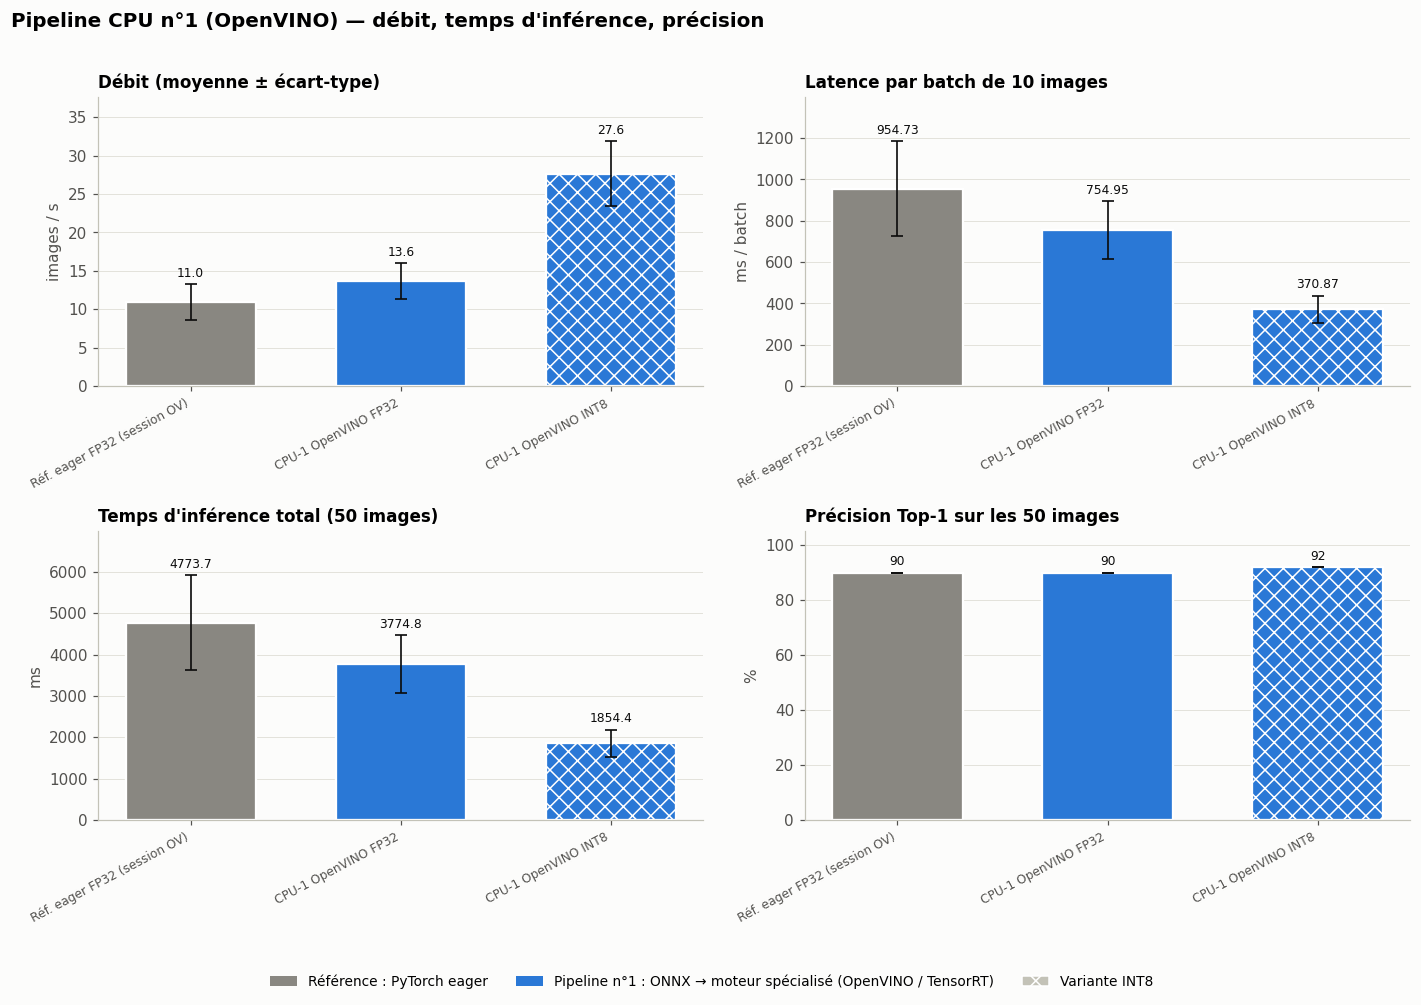

In [ ]:
fig_performance(ov_results, "Pipeline CPU n°1 (OpenVINO) — débit, temps d'inférence, précision", "ov_performance.png")

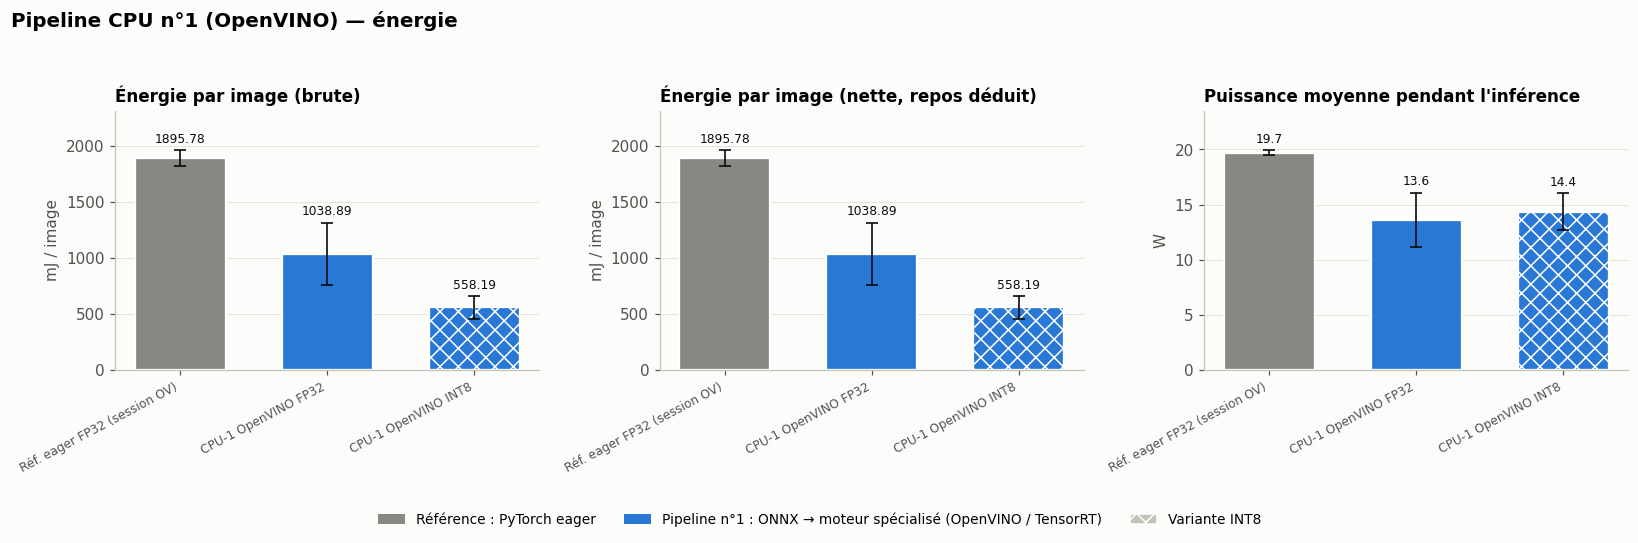

In [ ]:
fig_energy(ov_results, "Pipeline CPU n°1 (OpenVINO) — énergie", "ov_energie.png")

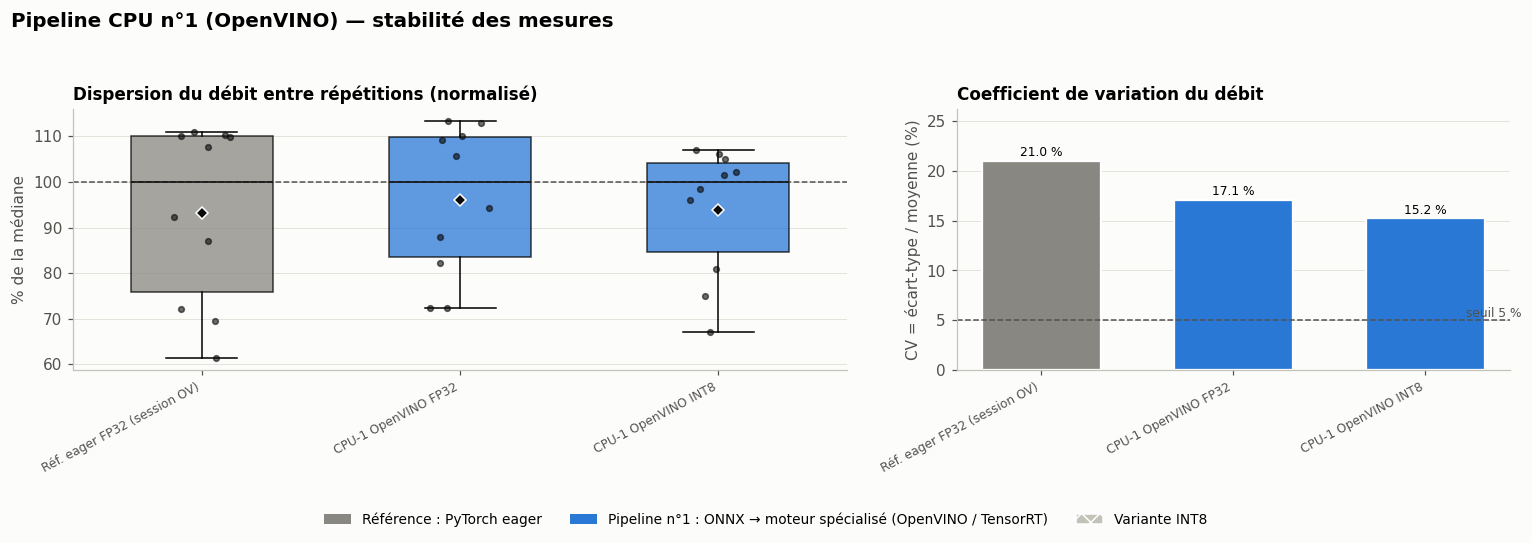

In [ ]:
fig_variability(ov_results, "Pipeline CPU n°1 (OpenVINO) — stabilité des mesures", "ov_variabilite.png")

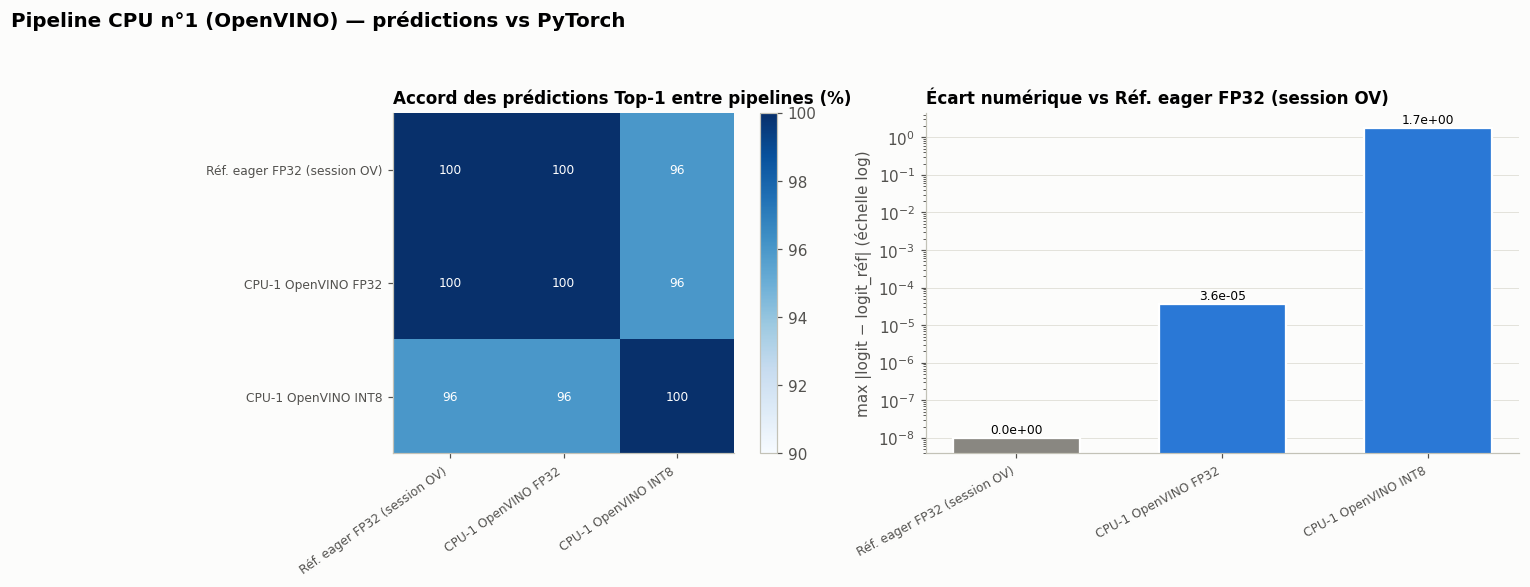

,accord_top1_vs_ref_%,max_|Δlogit|,moy_|Δlogit|,max_|Δproba|,top1_%
pipeline,,,,,
Réf. eager FP32 (session OV),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
CPU-1 OpenVINO FP32,100.0,3.58e-05,7.06e-06,7.09e-06,90.0
CPU-1 OpenVINO INT8,96.0,1.74e+00,3.77e-01,3.17e-01,92.0


In [ ]:
df_agree_ov = fig_agreement(ov_results, "cpu_ov_ref_eager", "Pipeline CPU n°1 (OpenVINO) — prédictions vs PyTorch",
                            "ov_predictions.png")
df_agree_ov

In [ ]:
auto_comments(ov_results, "cpu_ov_ref_eager")

Référence : Réf. eager FP32 (session OV) = 11.0 img/s

- Réf. eager FP32 (session OV) débit      11.0 img/s  (× 1.00 vs réf.)  CV 21.0 %  [7.2 ; 13.1]  Top-1 90 %  E/img 1895.78 mJ  → VARIABLE
- CPU-1 OpenVINO FP32          débit      13.6 img/s  (× 1.24 vs réf.)  CV 17.1 %  [10.3 ; 16.1]  Top-1 90 %  E/img 1038.89 mJ  → VARIABLE
- CPU-1 OpenVINO INT8          débit      27.6 img/s  (× 2.52 vs réf.)  CV 15.2 %  [19.8 ; 31.5]  Top-1 92 %  E/img 558.19 mJ  → VARIABLE

Pipeline le plus rapide : CPU-1 OpenVINO INT8
Écarts de précision Top-1 observés : {'Réf. eager FP32 (session OV)': '90 %', 'CPU-1 OpenVINO FP32': '90 %', 'CPU-1 OpenVINO INT8': '92 %'}


## 6. Comparaison des pipelines (section identique dans les deux notebooks)

Cette section recharge **tous les résultats présents dans le dossier `results`** : ceux de ce notebook, ceux de l'autre notebook CPU s'il a déjà été exécuté, et ceux des pipelines GPU s'ils ont été produits au même format (notebook GPU). **Exécutez-la à la fin du second notebook** pour obtenir la comparaison complète ; elle fonctionne aussi avec un seul pipeline disponible.

Chaque notebook Colab tourne sur **sa propre machine virtuelle** : on vérifie donc que le modèle de CPU est le même, et on présente l'**accélération par rapport à la référence eager mesurée dans la même session** (comparaison robuste même si les machines diffèrent un peu).

In [ ]:
CPU_KEYS = ["cpu_ov_ref_eager", "cpu1_openvino_fp32", "cpu1_openvino_int8",
            "cpu_pt_ref_eager", "cpu2_torchscript_fp32", "cpu2_compile_fp32", "cpu2_compile_freezing_fp32",
            "cpu2_compile_autotune_fp32"]
GPU_KEYS = ["gpu0_eager_fp32", "gpu1_trt_fp32", "gpu1_trt_fp16", "gpu2_torchscript_fp32",
            "gpu2_compile_fp32", "gpu2_compile_fp16", "gpu2_compile_autotune_fp32"]
REF_KEYS = ["cpu_ov_ref_eager", "cpu_pt_ref_eager", "gpu0_eager_fp32"]

all_results = load_results(CPU_KEYS + GPU_KEYS)
cpu_all = {k: v for k, v in all_results.items() if v["platform"] == "CPU"}
has_gpu = any(v["platform"] == "GPU" for v in all_results.values())
REF_KEY = next(k for k in REF_KEYS if k in all_results)

if "cpu1_openvino_fp32" not in all_results:
    print("ℹ Pipeline CPU n°1 (OpenVINO) pas encore exécuté : lancez son notebook puis relancez cette section.")
if "cpu2_compile_fp32" not in all_results:
    print("ℹ Pipeline CPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.")

cond = pd.DataFrame([{"pipeline": r["label"], "session": r.get("session_id"), "images": r["n_images"],
                      "batch": r["batch_size"], "warm-up": r["n_warmup"], "répétitions": r["n_runs"],
                      "SHA-256 entrées": r["test_sha256"][:12], "processeur": r["env"].get("cpu"),
                      "vCPU": r["env"].get("n_vcpu"), "GPU": r["env"].get("gpu", "—")}
                     for r in all_results.values()]).set_index("pipeline")
assert cond["SHA-256 entrées"].nunique() == 1, "Les pipelines n'ont pas utilisé les mêmes images !"
assert cond["batch"].nunique() == 1 and cond["images"].nunique() == 1, "Batch ou nombre d'images différent !"
print("✔ Mêmes 50 images, même prétraitement, même batch pour tous les pipelines.")
cpu_models = {r["env"].get("cpu") for r in cpu_all.values()}
if len(cpu_models) > 1:
    print("⚠ Les sessions CPU n'ont pas eu le même processeur :", cpu_models,
          "\n  → comparez surtout l'accélération vs eager de la même session, ou relancez pour obtenir le même CPU.")
cond

ℹ Pipeline CPU n°2 (PyTorch) pas encore exécuté : lancez son notebook puis relancez cette section.
✔ Mêmes 50 images, même prétraitement, même batch pour tous les pipelines.


,session,images,batch,warm-up,répétitions,SHA-256 entrées,processeur,vCPU,GPU
pipeline,,,,,,,,,
Réf. eager FP32 (session OV),ov_20261116-085931,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—
CPU-1 OpenVINO FP32,ov_20261116-085931,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—
CPU-1 OpenVINO INT8,ov_20261116-085931,50,10,5,10,117a8d622a14,Intel(R) Xeon(R) CPU @ 2.20GHz,2,—


In [ ]:
df_all = summary_table(all_results)
df_all.to_csv(f"{RESULTS}/summary_all.csv")
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 40)
df_all

,plateforme,précision,débit moy (img/s),débit σ,débit min,débit max,débit CV %,latence batch moy (ms),latence σ,latence min,latence max,temps 50 img moy (ms),temps σ,temps min,temps max,Top-1 moy %,Top-1 σ,E/image moy (mJ),E/image σ,E nette/image (mJ),puissance moy (W),méthode énergie
pipeline,,,,,,,,,,,,,,,,,,,,,,
Réf. eager FP32 (session OV),CPU,FP32,10.97,2.30,7.23,13.07,21.02,954.73,228.97,765.09,1383.26,4773.69,1144.87,3825.47,6916.34,90.0,0.0,1895.78,69.71,1895.78,19.70,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-1 OpenVINO FP32,CPU,FP32,13.63,2.33,10.27,16.11,17.12,754.95,139.99,620.78,973.53,3774.79,699.97,3103.91,4867.67,90.0,0.0,1038.89,277.17,1038.89,13.59,Estimation : 10 W par vCPU actif × temps CPU a...
CPU-1 OpenVINO INT8,CPU,INT8,27.63,4.21,19.76,31.49,15.24,370.87,65.77,317.53,506.06,1854.36,328.86,1587.65,2530.30,92.0,0.0,558.19,102.03,558.19,14.36,Estimation : 10 W par vCPU actif × temps CPU a...


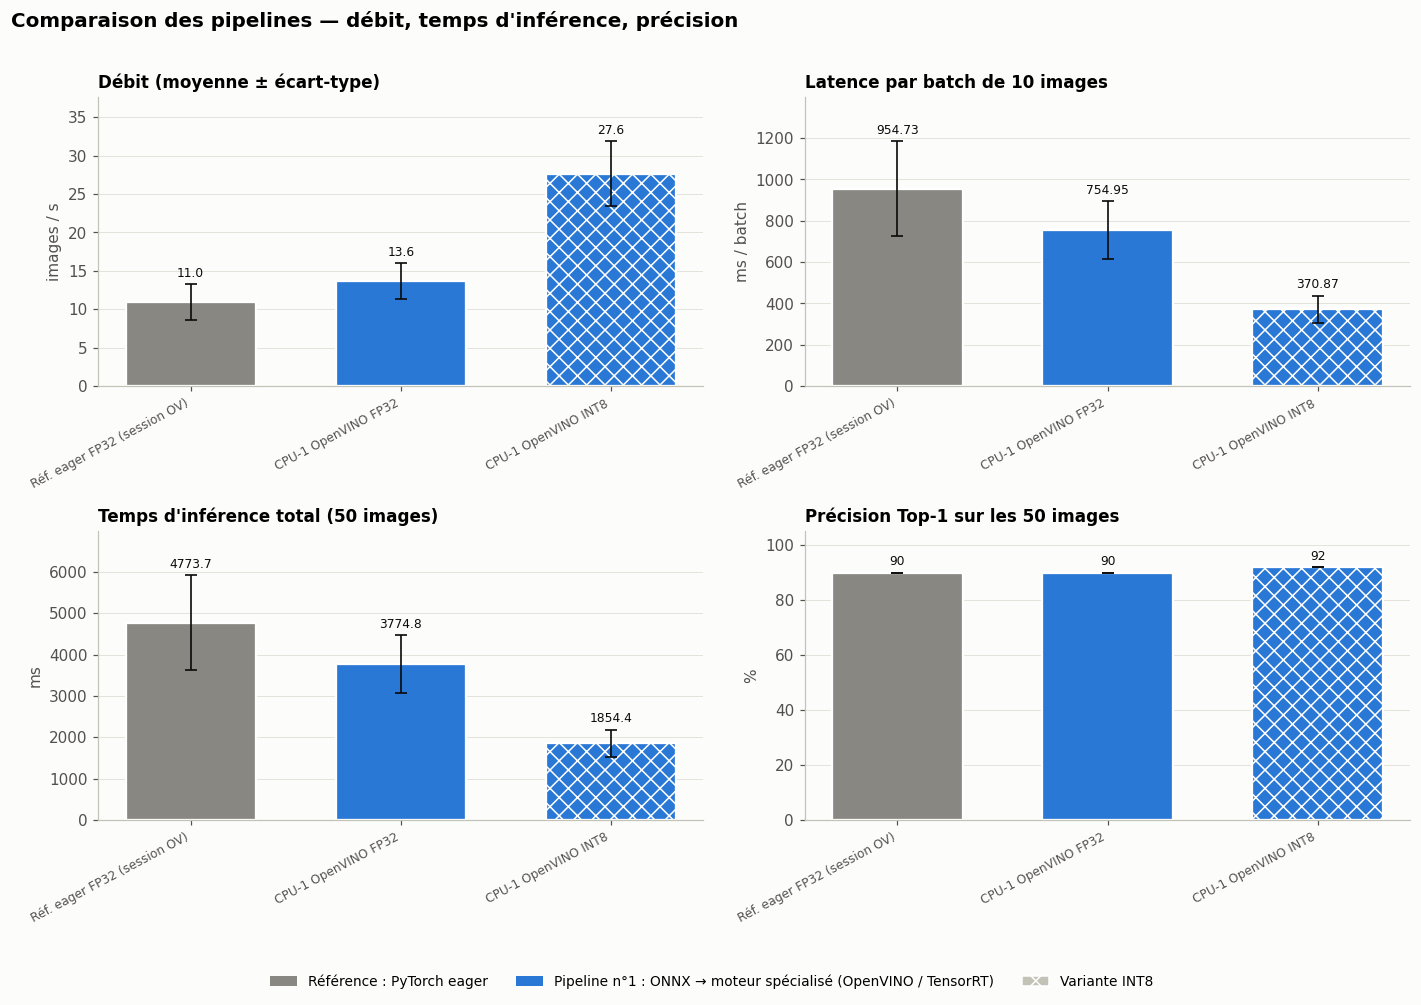

In [ ]:
fig_performance(all_results, "Comparaison des pipelines — débit, temps d'inférence, précision",
                "compare_performance.png", log=has_gpu)

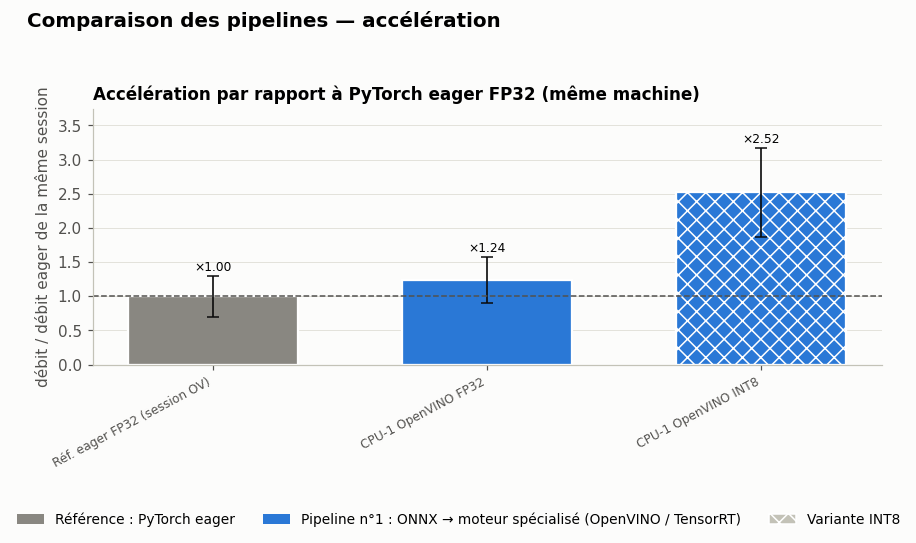

In [ ]:
fig_speedup(all_results, "Comparaison des pipelines — accélération", "compare_acceleration.png")

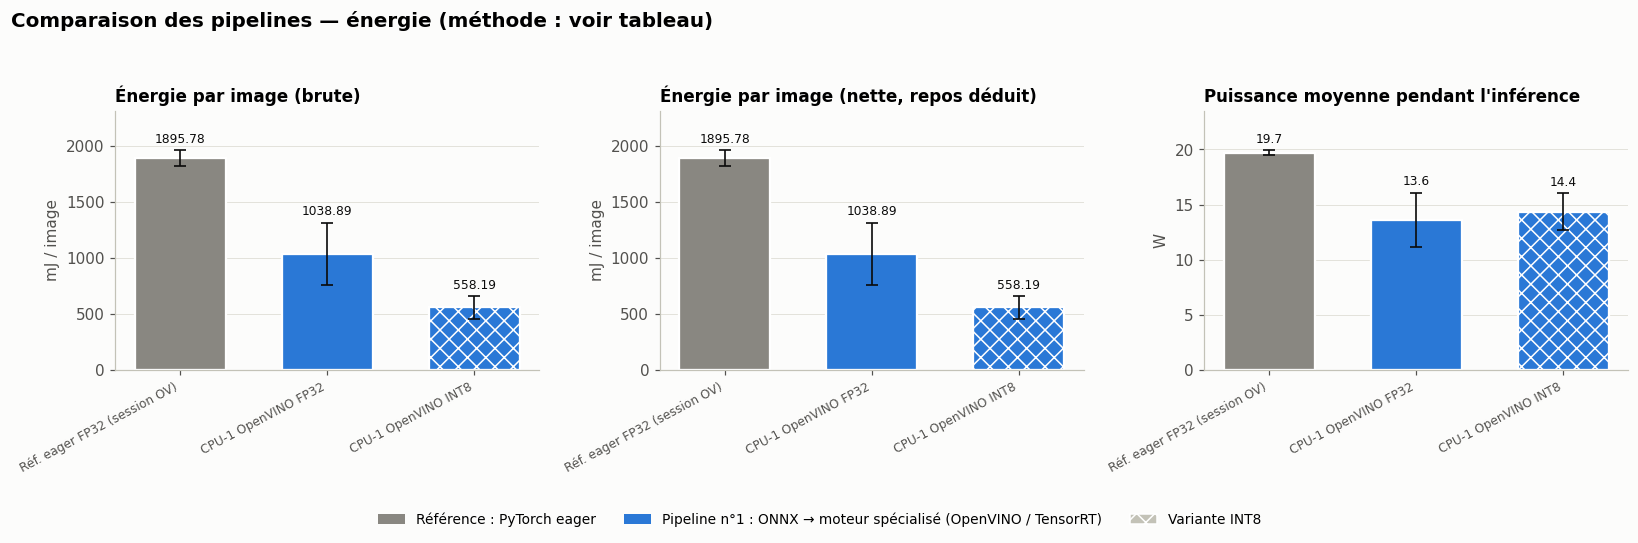

In [ ]:
fig_energy(all_results, "Comparaison des pipelines — énergie (méthode : voir tableau)", "compare_energie.png", log=has_gpu)

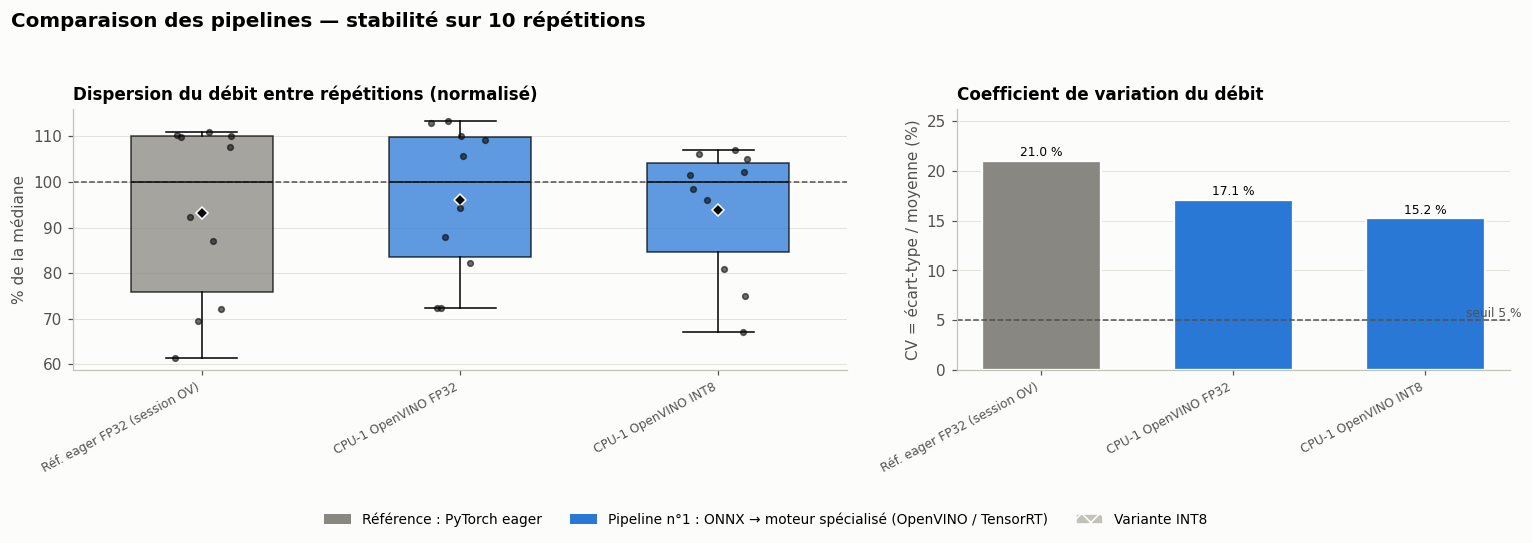

In [ ]:
fig_variability(all_results, "Comparaison des pipelines — stabilité sur 10 répétitions", "compare_variabilite.png")

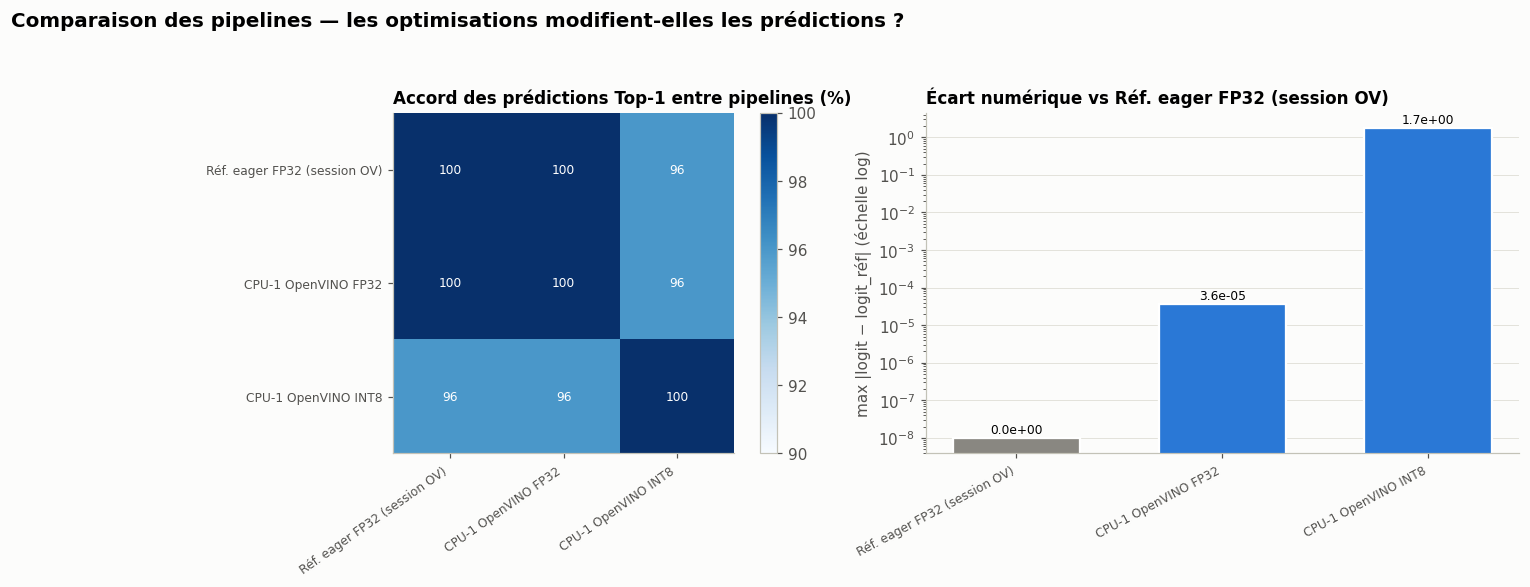

,accord_top1_vs_ref_%,max_|Δlogit|,moy_|Δlogit|,max_|Δproba|,top1_%
pipeline,,,,,
Réf. eager FP32 (session OV),100.0,0.00e+00,0.00e+00,0.00e+00,90.0
CPU-1 OpenVINO FP32,100.0,3.58e-05,7.06e-06,7.09e-06,90.0
CPU-1 OpenVINO INT8,96.0,1.74e+00,3.77e-01,3.17e-01,92.0


In [ ]:
df_agree = fig_agreement(all_results, REF_KEY, "Comparaison des pipelines — les optimisations modifient-elles les prédictions ?",
                         "compare_predictions.png")
df_agree

In [ ]:
# Images dont la prédiction diffère entre pipelines
logits_all = {k: np.load(f"{RESULTS}/{k}_logits.npy") for k in all_results}
ref_pred = logits_all[REF_KEY].argmax(1)
diff_idx = sorted({int(i) for v in logits_all.values() for i in np.where(v.argmax(1) != ref_pred)[0]})
if not diff_idx:
    print("Aucune image ne change de classe prédite : tous les pipelines donnent les mêmes 50 prédictions.")
else:
    rows = []
    for i in diff_idx:
        row = {"image": i, "vraie classe": CLASSES[Y50_NP[i]]}
        row.update({all_results[k]["label"]: CLASSES[int(v[i].argmax())] for k, v in logits_all.items()})
        rows.append(row)
    display(pd.DataFrame(rows).set_index("image"))

,vraie classe,Réf. eager FP32 (session OV),CPU-1 OpenVINO FP32,CPU-1 OpenVINO INT8
image,,,,
6,deer,bird,bird,deer
40,deer,bird,bird,horse


### Exécutions indépendantes (variabilité entre sessions)
Les 10 répétitions d'un même notebook ont lieu dans **une même session** (même machine, même processus). Pour mesurer la reproductibilité **entre exécutions indépendantes**, relancez chaque notebook dans une **nouvelle session** (`Exécution` → `Déconnecter et supprimer l'environnement d'exécution`, puis `Tout exécuter`) au moins **3 fois**. Chaque exécution ajoute une ligne par pipeline dans `results/history/`, et le tableau ci-dessous calcule moyenne, écart-type, min et max **entre sessions**.

In [ ]:
hist_rows, hist_agg = history_table()
if hist_rows.empty:
    print("Aucun historique.")
else:
    display(hist_rows)
    display(hist_agg)
    hist_agg.to_csv(f"{RESULTS}/summary_inter_sessions.csv")
    multi = hist_agg[hist_agg["sessions"] >= 2]
    if len(multi):
        fig, ax = plt.subplots(figsize=(11, 4.5))
        for i, (lab, g) in enumerate(hist_rows.groupby("pipeline")):
            ax.scatter(np.full(len(g), i), g["débit (img/s)"], s=30, color="#2a78d6", zorder=3)
            ax.errorbar(i, g["débit (img/s)"].mean(), yerr=g["débit (img/s)"].std() if len(g) > 1 else 0,
                        fmt="D", color="#0b0b0b", capsize=5)
        ax.set_xticks(range(hist_rows["pipeline"].nunique()))
        ax.set_xticklabels(sorted(hist_rows["pipeline"].unique()), rotation=28, ha="right", fontsize=8)
        ax.set_ylabel("débit moyen de la session (img/s)")
        ax.set_title("Débit par session (points) et moyenne ± écart-type entre sessions", loc="left",
                     fontsize=11, fontweight="bold")
        ax.grid(axis="x", visible=False)
        fig.tight_layout(); fig.savefig(f"{FIGS}/inter_sessions.png", bbox_inches="tight"); plt.show()
    else:
        print("Une seule session par pipeline pour l'instant : relancez le notebook dans une nouvelle session.")

,pipeline,session,cpu,débit (img/s),latence batch (ms),Top-1 %
0,CPU-1 OpenVINO FP32,ov_20261116-085931,Intel(R) Xeon(R) CPU @ 2.20GHz,13.63,754.95,90.0
1,CPU-1 OpenVINO INT8,ov_20261116-085931,Intel(R) Xeon(R) CPU @ 2.20GHz,27.63,370.87,92.0
2,Réf. eager FP32 (session OV),ov_20261116-085931,Intel(R) Xeon(R) CPU @ 2.20GHz,10.97,954.73,90.0


,sessions,débit_moy,débit_σ_inter_sessions,débit_min,débit_max,latence_moy,latence_σ_inter_sessions,top1_moy,débit_CV_inter_%
pipeline,,,,,,,,,
CPU-1 OpenVINO FP32,1,13.63,NaN,13.63,13.63,754.95,NaN,90.0,NaN
CPU-1 OpenVINO INT8,1,27.63,NaN,27.63,27.63,370.87,NaN,92.0,NaN
Réf. eager FP32 (session OV),1,10.97,NaN,10.97,10.97,954.73,NaN,90.0,NaN


Une seule session par pipeline pour l'instant : relancez le notebook dans une nouvelle session.


In [ ]:
auto_comments(all_results, REF_KEY)
print("\nFigures :", FIGS, "\nTableaux :", f"{RESULTS}/summary_all.csv")

Référence : Réf. eager FP32 (session OV) = 11.0 img/s

- Réf. eager FP32 (session OV) débit      11.0 img/s  (× 1.00 vs réf.)  CV 21.0 %  [7.2 ; 13.1]  Top-1 90 %  E/img 1895.78 mJ  → VARIABLE
- CPU-1 OpenVINO FP32          débit      13.6 img/s  (× 1.24 vs réf.)  CV 17.1 %  [10.3 ; 16.1]  Top-1 90 %  E/img 1038.89 mJ  → VARIABLE
- CPU-1 OpenVINO INT8          débit      27.6 img/s  (× 2.52 vs réf.)  CV 15.2 %  [19.8 ; 31.5]  Top-1 92 %  E/img 558.19 mJ  → VARIABLE

Pipeline le plus rapide : CPU-1 OpenVINO INT8
Écarts de précision Top-1 observés : {'Réf. eager FP32 (session OV)': '90 %', 'CPU-1 OpenVINO FP32': '90 %', 'CPU-1 OpenVINO INT8': '92 %'}

Figures : /content/drive/MyDrive/TP_Deploiement_IA/figures 
Tableaux : /content/drive/MyDrive/TP_Deploiement_IA/results/summary_all.csv


### (Optionnel) Sans Google Drive : récupérer les fichiers pour l'autre notebook
Si `USE_DRIVE = False`, téléchargez l'archive et importez-la dans l'autre notebook (cellule équivalente au début).

In [ ]:
if not USE_DRIVE:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/TP_Deploiement_IA", "zip", ROOT)
    files.download("/content/TP_Deploiement_IA.zip")

## 7. Analyse — Pipeline CPU n°1 (PyTorch → ONNX → OpenVINO) sur Colab CPU

*Environnement : Google Colab, Intel Xeon @ 2,20 GHz, 2 vCPU (AVX2), PyTorch 2.14.1+cpu, OpenVINO 2026.4.1. Session `ov_20261116-085931`. Protocole commun : 50 images CIFAR-10, batch 10, 5 passes de warm-up, 10 passes mesurées, 3 mesures d'énergie de 10 s. RAPL n'étant pas accessible, l'énergie est **estimée** (10 W par vCPU actif × temps CPU).*

| Variante | Débit (img/s) moy ± σ | [min ; max] | CV | Latence / batch (ms) | Accélération | Top-1 | Énergie / image (mJ, estimée) |
|---|---|---|---|---|---|---|---|
| PyTorch eager FP32 (réf.) | 10,97 ± 2,30 | [7,23 ; 13,07] | 21,0 % | 954,7 ± 229,0 | ×1,00 | 90 % | 1 896 ± 70 |
| OpenVINO FP32 | 13,63 ± 2,33 | [10,27 ; 16,11] | 17,1 % | 755,0 ± 140,0 | ×1,24 | 90 % | 1 039 ± 277 |
| OpenVINO INT8 | 27,63 ± 4,21 | [19,76 ; 31,49] | 15,2 % | 370,9 ± 65,8 | **×2,52** | 92 % | 558 ± 102 |

**A. Débit et temps d'inférence**

* **OpenVINO FP32 : ×1,24** (13,6 contre 11,0 img/s ; latence par batch 955 → 755 ms, −21 %). Le gain est cohérent sur la latence et sur le temps total : le temps des 50 images vaut bien environ 5 fois la latence d'un batch (4 774 ms ≈ 5 × 954,7 ms pour eager, 3 775 ms ≈ 5 × 755 ms pour OpenVINO).
* **Ce qu'a fait OpenVINO (4.3)** : les 49 nœuds ONNX (20 Conv, 17 Relu, 8 Add, MaxPool, GlobalAveragePool, Flatten, Gemm) deviennent un graphe compilé dont les couches de calcul sont 20 Convolution, 1 Pooling, 1 Reduce (moyenne globale), 1 FullyConnected et 2 Reorder (110 entrées au total avec les 64 constantes et 21 Reshape). **Il ne reste aucune couche ReLU ni addition** : les 17 ReLU et les 8 additions résiduelles sont fusionnées dans les convolutions, ce qui évite autant de passes en mémoire. La BatchNorm avait déjà été repliée dans les poids lors de l'export ONNX (constant folding). Les 2 Reorder convertissent l'entrée et la sortie vers et depuis la disposition mémoire en blocs utilisée par les kernels AVX2.
* **Kernels oneDNN (4.5)** : sur les 614 ms profilées pour un batch, **97,6 % du temps (599 ms) est passé dans les convolutions `brgconv_avx2_f32`** (17 appels), plus 7,6 ms dans les convolutions 1×1 `brgconv_avx2_1x1_f32` (3 appels) ; MaxPool, Reorder, moyenne et couche dense pèsent moins de 3 %. C'est ce qui limite le gain FP32 : PyTorch eager confie déjà ces convolutions à oneDNN, si bien qu'OpenVINO ne gagne que sur les opérations élémentaires, la disposition mémoire et l'overhead Python (un seul appel natif par batch).
* **INT8 : ×2,52** (27,6 img/s, 371 ms par batch). La quantification post-entraînement (NNCF, 28 s) exécute la majorité des couches en entiers 8 bits (26 couches u8 et 21 i8) : quatre fois moins d'octets à déplacer et davantage de valeurs traitées par instruction. C'est la seule variante CPU dont le débit se détache nettement des autres.
* **Coûts de mise en place** : export ONNX 1,7 s, `read_model` 0,36 s, `compile_model` 0,83 s, soit environ 3 s, négligeables devant un service qui tourne longtemps (le temps total des 50 images est déjà de 3,8 s). La quantification INT8 (28 s) est amortie après environ 500 images.

**B. Qualité des prédictions**

* **FP32** : écart maximal des logits 3,6·10⁻⁵ (moyen 7,1·10⁻⁶), accord Top-1 de 100 % avec PyTorch et même Top-1 (90 %). L'écart vient seulement de l'ordre des opérations flottantes (fusions, autres algorithmes de convolution), pas d'une perte d'information.
* **INT8** : écart maximal des logits 1,74 (moyen 0,38, écart maximal de probabilité 0,32) et **accord de 96 % : 2 prédictions sur 50 changent**. Le Top-1 passe à 92 %, mais ce n'est pas un gain de précision : sur 50 images, une image vaut 2 points, et ce changement est dans le bruit d'un échantillon aussi petit. Il faudrait évaluer l'INT8 sur tout le jeu de test pour mesurer sa perte de précision réelle.

**C. Énergie**

* Méthode : **estimation** (10 W par vCPU actif × temps CPU actif lu par psutil), car RAPL n'est pas exposé sur la VM Colab. Elle compare correctement les variantes entre elles, mais sa valeur absolue dépend de l'hypothèse de 10 W.
* Énergie par image : 1 896 mJ (eager) → **1 039 mJ en OpenVINO FP32 (−45 %)** → **558 mJ en INT8 (−71 %)**. La baisse dépasse le gain de débit, car la puissance estimée baisse aussi (19,7 W pour eager, 13,6 W et 14,4 W pour OpenVINO) : OpenVINO consomme moins de temps CPU pour le même travail, les deux vCPU n'étant pas occupés en permanence. E = P × t : moins de puissance et moins de temps.

**D. Stabilité**

* CV du débit : 21,0 % (eager), 17,1 % (FP32), 15,2 % (INT8) → **mesures très variables** (seuil de 5 %). Les passes s'écartent jusqu'à −34 % et +19 % de la moyenne. Causes : VM de 2 vCPU partagée avec d'autres utilisateurs (« voisins bruyants »), fréquence turbo variable, interruptions de l'ordonnanceur, alors que l'inférence occupe les deux cœurs.
* Intervalles [min ; max] : eager [7,2 ; 13,1] et OpenVINO FP32 [10,3 ; 16,1] **se chevauchent** : le gain FP32 de ×1,24 n'est pas significatif avec 10 passes. L'INT8 [19,8 ; 31,5] ne chevauche aucune variante FP32 : son gain est net malgré la variabilité.
* Entre sessions : la référence eager mesurée dans le notebook CPU n°2 (autre session, même type de VM) vaut 12,6 img/s contre 11,0 ici, soit 15 % d'écart, du même ordre que la variabilité interne. C'est pourquoi on compare les pipelines par leur accélération par rapport à la référence de leur propre session.
* **Conclusion** : sur ce CPU, OpenVINO apporte un gain modeste en FP32 (×1,24, non significatif vu la variabilité) mais une forte réduction de l'énergie estimée, et l'INT8 double le débit (×2,52) au prix de 2 prédictions modifiées sur 50. Le GPU T4 reste 78 à 93 fois plus rapide à implémentation égale (voir les notebooks GPU).